MSDS 7331 Machine Learning I

Instructor: Nedelina Teneva

Koosha Tabesh, Moinak Ghosh, Jacqueline Vu

# Lab One: Visualization and Data Preprocessing
## Forest Cover Type Dataset

Performing analysis on the Covertype dataset, we will evaluate feature distributions, generate descriptive visualizations, and draw actionable insights from the resulting patterns. Following the CRISP-DM framework, we are just focusing on the Business Understanding and Data Understanding sections.

**A note on sources.** For the general workflow and structure of this
analysis (loading and inspecting the data, checking data quality, computing
statistics, visualizing attributes, exploring relationships, then PCA/LDA for
the dimensionality-reduction section), we followed the pattern demonstrated
in the course companion notebooks `01__Pandas.ipynb`,
`02__DataVisualization.ipynb`, and `03__Dimension_Reduction.ipynb`, applying
it here to the Covertype dataset instead of the Titanic/Iris/heart disease
datasets those notebooks use. A few specific pieces of code and technique
were adapted more directly from those notebooks, or from other sources we
found online. Therefore, we call those out with a comment at the exact cell
where they are used, rather than only listing them here.

## 1. Project/Objective Understanding (Business Understanding)

**Dataset overview:** This is the UCI Covertype dataset, 581,012 rows, one row
per 30m x 30m cell of forest land, spread across four wilderness areas of the
Roosevelt National Forest in northern Colorado: Rawah, Neota, Comanche Peak,
and Cache la Poudre. Each cell is described purely by cartographic variables,
the kind of information that's already sitting in a GIS system: elevation,
slope, and aspect (compass direction the slope faces), horizontal and vertical
distance to the nearest surface water, distance to the nearest road, distance
to the nearest historical wildfire ignition point, three hillshade readings
(simulated sunlight intensity at 9am, noon, and 3pm), which of the four
wilderness areas the cell falls in, and one of 40 USFS soil classification
codes. Nothing here comes from satellite or aerial imagery. It is
data that a land manager could pull from existing maps and survey records without
ever visiting the site.

The original documentation file that ships with this dataset
(`covtype.info`) was written by the data's original source, Jock A. Blackard
(USFS / Colorado State University). It confirms these four wilderness areas
were chosen specifically because they have minimal human caused disturbance
(no significant logging or replanting), so the forest cover types actually
present are a result of natural ecological processes like elevation,
sun exposure, and soil, rather than management decisions. That matters for
this analysis as any elevation/terrain relationship found later reflects real
ecology, not a side effect of forestry practices.

**Why this data was collected:** Straight from Blackard's dissertation
abstract, land managers need an inventory of what is growing on a piece of
land in order to plan things like wildlife habitat assessments, fire risk
management, and timber/recreation planning. However, they usually only have that
kind of survey data for land inside their own jurisdiction, not for
neighboring parcels or inholdings they don't manage but still need to
understand. Getting that inventory the traditional way by either sending someone out to
do a field survey or paying for aerial photo interpretation is slow and
expensive at the scale of an entire national forest. Therefore, the actual question
this dataset was built to answer is: *is it enough for a predictive model to be useful by relying only cheap
cartographic variables that are already on file to substitute for that
expensive survey step in order to predict forest cover type accurately or not?*

**Target variable:** `Cover_Type`, a 7-class label giving the single dominant
tree species type for each cell:
1. Spruce/Fir
2. Lodgepole Pine
3. Ponderosa Pine
4. Cottonwood/Willow
5. Aspen
6. Douglas-fir
7. Krummholz (stunted, wind shaped trees found right at the treeline)

This makes it a multi-class classification problem, not a binary one.

**How to know if useful knowledge was mined:** Accuracy numbers alone do not
answer this question. What would actually build our confidence that a model
learned something real, rather than a spurious pattern in this particular
sample, is whether the patterns it relies on line up with known forest
ecology. We are able to check this here because our analysis independently
confirms several textbook ecological relationships directly from the data
itself in sections 2.6 through 2.8: tree species zonation by elevation band,
aspect driven differences in sun exposure, and soil type tracking climatic
zone. Therefore, if a model's most important features turn out to be
elevation, wilderness area, and roadway distance, the same attributes we
found here to carry real signal, that would be a much stronger sign of
genuinely useful, generalizable knowledge than a high accuracy score by
itself. On the other hand, a model that instead relied heavily on a weak or
ecologically meaningless attribute would be a red flag, even with good
accuracy on this particular data.

**How to measure success:** The original study gives real numbers to anchor
to instead of guessing. Blackard & Dean (2000) compared a neural network
against linear discriminant analysis on this exact prediction task and got
70.58% overall accuracy with the neural network versus 58.38% with LDA. Therefore,
"accuracy somewhere in the high 60s to low 70s" is roughly what counted as a
strong result when this problem was first studied. Knowing that, the class
distribution here is quite imbalanced, which has been confirmed with real numbers in section
2.4. Therefore, raw accuracy alone can be misleading. A model could score deceptively
well just by always guessing the two largest classes. Metrics like macro-
averaged F1 or a per-class confusion matrix are more honest because they
would actually expose whether a model is failing on the rarer cover types, which is
something the original study's headline accuracy number would not show on its
own.

## 2. Data Understanding

### 2.1 Loading the data

The dataset was fetched via the official `ucimlrepo` package rather than having it pulled from the local drive. This dataset originally has the features (`X`) and target (`y`) in seperate files, so they have been combined into one dataframe.

In [1]:
!pip install ucimlrepo -q

import pandas as pd
import numpy as np

# fetch the dataset directly from UCI; fall back to a local cached copy if
# there is no internet access in this environment
try:
    from ucimlrepo import fetch_ucirepo
    covertype = fetch_ucirepo(id=31)
    df = pd.concat([covertype.data.features, covertype.data.targets], axis=1)  # combine features + target into one dataframe
except Exception:
    df = pd.read_csv('covtype.csv')

df.head()

,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Wilderness_Area2,Wilderness_Area3,Wilderness_Area4,Cover_Type
0,2596,51,3,258,0,510,221,232,148,6279,...,0,0,0,0,0,0,0,0,0,5
1,2590,56,2,212,-6,390,220,235,151,6225,...,0,0,0,0,0,0,0,0,0,5
2,2804,139,9,268,65,3180,234,238,135,6121,...,0,0,0,0,0,0,0,0,0,2
3,2785,155,18,242,118,3090,238,238,122,6211,...,0,0,0,0,0,0,0,0,0,2
4,2595,45,2,153,-1,391,220,234,150,6172,...,0,0,0,0,0,0,0,0,0,5


In [2]:
# quick shape/dtype check before doing anything else
print(df.shape)
df.info()

(581012, 55)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 581012 entries, 0 to 581011
Data columns (total 55 columns):
 #   Column                              Non-Null Count   Dtype
---  ------                              --------------   -----
 0   Elevation                           581012 non-null  int64
 1   Aspect                              581012 non-null  int64
 2   Slope                               581012 non-null  int64
 3   Horizontal_Distance_To_Hydrology    581012 non-null  int64
 4   Vertical_Distance_To_Hydrology      581012 non-null  int64
 5   Horizontal_Distance_To_Roadways     581012 non-null  int64
 6   Hillshade_9am                       581012 non-null  int64
 7   Hillshade_Noon                      581012 non-null  int64
 8   Hillshade_3pm                       581012 non-null  int64
 9   Horizontal_Distance_To_Fire_Points  581012 non-null  int64
 10  Wilderness_Area1                    581012 non-null  int64
 11  Soil_Type1                          581

In [3]:
# print the official UCI metadata/variable descriptions if we fetched live;
# skip quietly if we fell back to the local CSV (no metadata object then)
try:
    print(covertype.metadata)
    print(covertype.variables)
except NameError:
    pass

{'uci_id': 31, 'name': 'Covertype', 'repository_url': 'https://archive.ics.uci.edu/dataset/31/covertype', 'data_url': 'https://archive.ics.uci.edu/static/public/31/data.csv', 'abstract': 'Classification of pixels into 7 forest cover types based on attributes such as elevation, aspect, slope, hillshade, soil-type, and more.', 'area': 'Biology', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 581012, 'num_features': 54, 'feature_types': ['Categorical', 'Integer'], 'demographics': [], 'target_col': ['Cover_Type'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 1998, 'last_updated': 'Sat Mar 16 2024', 'dataset_doi': '10.24432/C50K5N', 'creators': ['Jock Blackard'], 'intro_paper': None, 'additional_info': {'summary': 'Predicting forest cover type from cartographic variables only (no remotely sensed data).  The actual forest cover type for a given observation (30 x 30 meter cell) was determined from

Shown above is the official UCI attribute documentation, which is needed for checking against the table in section
2.2.

### 2.2 Meaning and type of each attribute

Although the original dataset contain 581k rows by 55 columns, the `covtype.info` doc that ships with this dataset
describes it as "12 measures, but 54 columns of data." That is because the
one-hot `Wilderness_Area` and `Soil_Type` dummy columns (4 + 40 binary columns)
are just 2 underlying categorical measures that happen to be
pre-encoded into separate 0/1 columns, on top of the 10 real quantitative
measures. Here's the full attribute list with type and meaning:

| Attribute | Type | Meaning / values |
|---|---|---|
| `Elevation` | Numeric (ratio) | Elevation in meters |
| `Aspect` | Numeric (circular, 0-360) | Compass direction the slope faces, in degrees azimuth |
| `Slope` | Numeric (ratio) | Slope in degrees |
| `Horizontal_Distance_To_Hydrology` | Numeric (ratio) | Horizontal distance (m) to nearest surface water |
| `Vertical_Distance_To_Hydrology` | Numeric (interval, can be negative) | Vertical distance (m) to nearest surface water |
| `Horizontal_Distance_To_Roadways` | Numeric (ratio) | Horizontal distance (m) to nearest road |
| `Hillshade_9am` / `Hillshade_Noon` / `Hillshade_3pm` | Numeric (0-255) | Simulated illumination index at 9am/noon/3pm on the summer solstice |
| `Horizontal_Distance_To_Fire_Points` | Numeric (ratio) | Horizontal distance (m) to nearest wildfire ignition point |
| `Wilderness_Area1..4` (one-hot) | Categorical (nominal, 4 levels) | Which of 4 wilderness areas the cell is in |
| `Soil_Type1..40` (one-hot) | Categorical (nominal, 40 levels) | USFS Ecological Landtype Unit (ELU) soil classification |
| `Cover_Type` | Categorical (nominal, 7 levels) - target | Dominant forest cover type |

It is worth flagging `Aspect` early as `Aspect` is a circular variable. Since 0 degrees and 360 degrees point in the same direction, a plain mean or variance computed on it
does not mean much on its own. This gets handled properly later with a sin/cos
decomposition in section 2.8.

The soil type codes are not arbitrary numbers
either. The documentation shows they are built from real USFS Ecological
Landtype Unit codes, where the first digit encodes a climatic zone (lower
montane, montane, subalpine, alpine, etc.) and the second digit encodes a
geologic zone (alluvium, glacial, shale, igneous, etc.). That decoding gets
used in section 2.8 to turn 40 sparse dummy columns into two much more
meaningful categorical features.

For the rest of this analysis, we collapse the one-hot wilderness/soil columns into two single categorical columns since that makes grouping and
plotting far easier than working with 44 separate binary columns.

In [4]:
# one-hot columns for wilderness area (4) and soil type (40)
wilderness_cols = [c for c in df.columns if c.startswith('Wilderness_Area')]
soil_cols = [c for c in df.columns if c.startswith('Soil_Type')]
# the 10 real quantitative measures
numeric_cols = ['Elevation','Aspect','Slope','Horizontal_Distance_To_Hydrology',
                'Vertical_Distance_To_Hydrology','Horizontal_Distance_To_Roadways',
                'Hillshade_9am','Hillshade_Noon','Hillshade_3pm',
                'Horizontal_Distance_To_Fire_Points']

print(f"{len(numeric_cols)} numeric attributes, {len(wilderness_cols)} wilderness-area "
      f"dummies, {len(soil_cols)} soil-type dummies, 1 target (Cover_Type)")

# collapse each one-hot block back into a single categorical column (argmax
# finds the position of the single "1"; +1 converts 0-based position to the
# dataset's 1-based numbering)
df['wilderness_area'] = df[wilderness_cols].values.argmax(axis=1) + 1
df['soil_type'] = df[soil_cols].values.argmax(axis=1) + 1

cover_type_names = {1: 'Spruce/Fir', 2: 'Lodgepole Pine', 3: 'Ponderosa Pine',
                     4: 'Cottonwood/Willow', 5: 'Aspen', 6: 'Douglas-fir', 7: 'Krummholz'}
df['cover_type_name'] = df['Cover_Type'].map(cover_type_names)
df[['Elevation','Aspect','wilderness_area','soil_type','Cover_Type','cover_type_name']].head()

10 numeric attributes, 4 wilderness-area dummies, 40 soil-type dummies, 1 target (Cover_Type)


,Elevation,Aspect,wilderness_area,soil_type,Cover_Type,cover_type_name
0,2596,51,1,29,5,Aspen
1,2590,56,1,29,5,Aspen
2,2804,139,1,12,2,Lodgepole Pine
3,2785,155,1,30,2,Lodgepole Pine
4,2595,45,1,29,5,Aspen


### 2.3 Data quality: missing values, duplicates, outliers

In [5]:
# standard missing-value and duplicate-row check
print("Missing values per column (showing only non-zero):")
missing = df.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else "None found.")
print()
print("Duplicate rows:", df.duplicated().sum())

Missing values per column (showing only non-zero):
None found.

Duplicate rows: 0


After checking for missing values and duplicate rows, there are zero missing values and zero duplicate rows. This makes sense because every value here comes straight out of GIS raster data for a fixed 30m
grid. There are no survey gaps or manual data entry steps that could
introduce gaps or repeated records the way there would be with
human reported survey data.

One thing that isn't exactly "missing data" but is still worth checking are
all the 40 soil types that are represented in this data because there is a possibility that some of the 40
possible codes are simply absent from these specific four wilderness areas.

In [6]:
# check whether all 40 possible soil types actually occur in this data,
# and which ones are rarest
used_soil_types = df['soil_type'].nunique()
print(f"Soil types actually present in the data: {used_soil_types} / 40 possible")
print()
soil_counts = df['soil_type'].value_counts()
print("Rarest 5 soil types by count:")
print(soil_counts.tail(5))

Soil types actually present in the data: 40 / 40 possible

Rarest 5 soil types by count:
soil_type
37    298
8     179
36    119
7     105
15      3
Name: count, dtype: int64


All 40 soil types show up at least once, but a handful are extremely rare:
just a few hundred cells each out of 581k. That is not an error as that reflects
genuine geological scarcity since some soil types simply are not common
across these particular wilderness areas. This is worth keeping in mind for later as
grouping the rarest ones into broader categories (section 2.8) will carry more
statistical signal than treating each one as its own separate category.

We then check for outliers in the 10 numeric columns by using
boxplots and checking their IQRs.

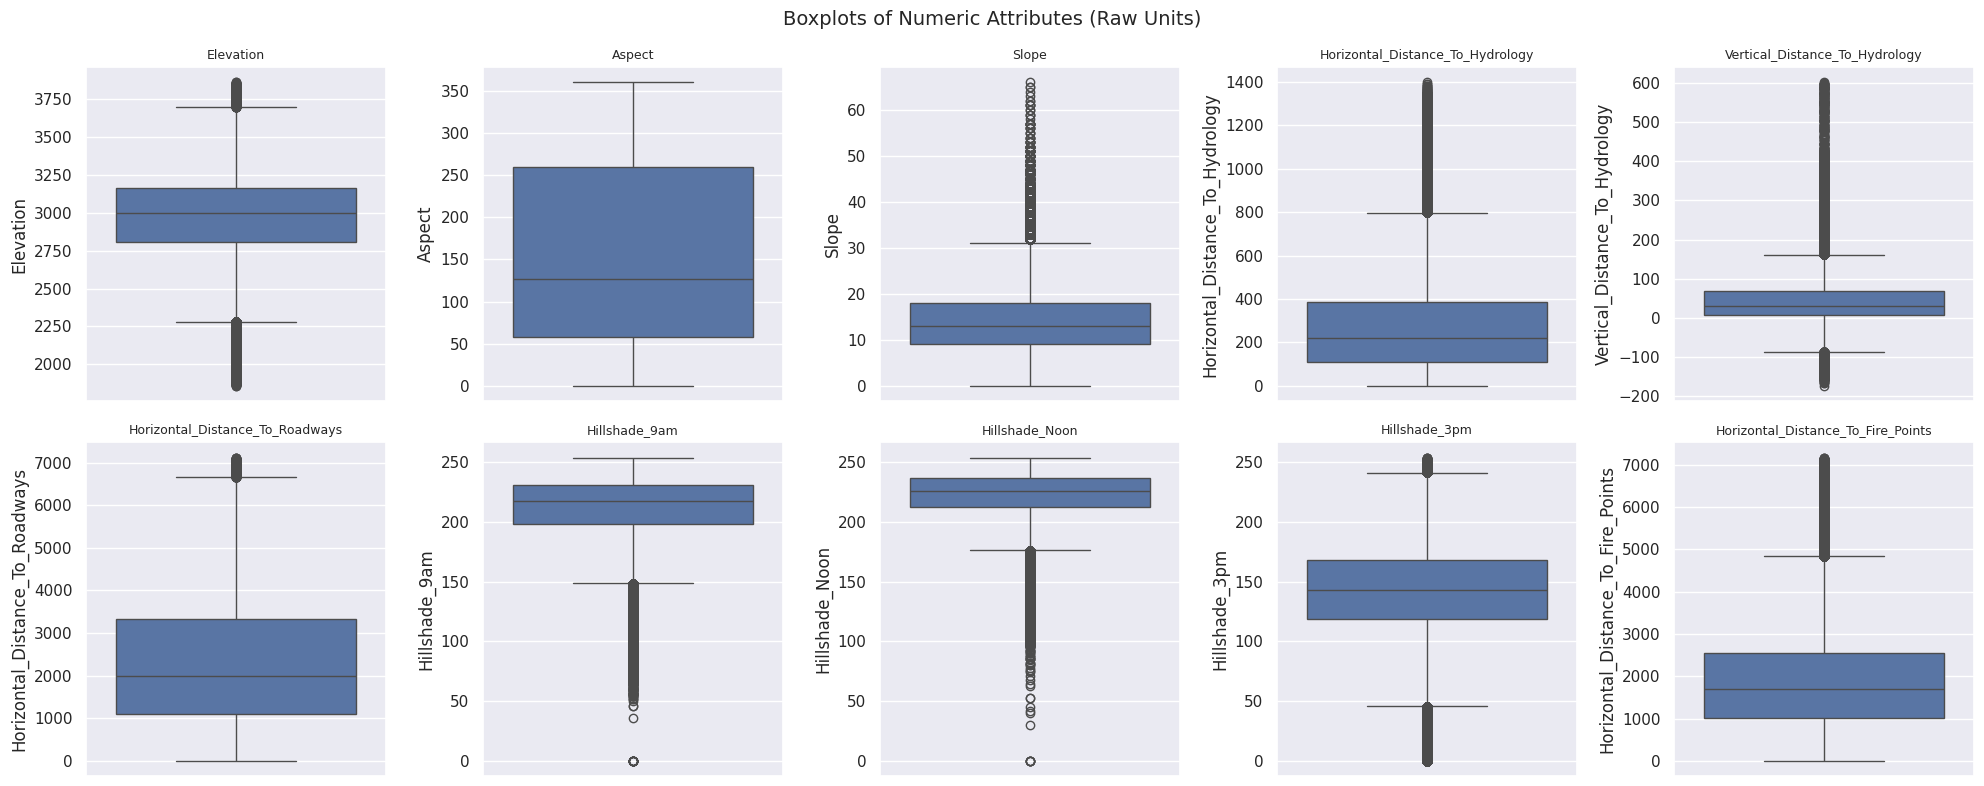

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style='darkgrid')

# one boxplot per numeric attribute, on each attribute's own raw scale
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.ravel()
for i, col in enumerate(numeric_cols):
    sns.boxplot(y=df[col], ax=axes[i])
    axes[i].set_title(col, fontsize=9)
fig.suptitle('Boxplots of Numeric Attributes (Raw Units)', fontsize=14)
plt.tight_layout()
plt.show()

The boxplots above are each on their own raw scale (meters, degrees, or a
0-255 index), so we cannot directly compare how "outlier-heavy" one attribute
is relative to another just by looking at them side by side. To make that
comparison fair, we standardize every attribute using the modified z-score,
which is based on the median and the median absolute deviation (MAD) rather
than the mean and standard deviation. We use the modified version specifically
because several of these attributes are heavily skewed, and a regular z-score
would have its mean and standard deviation pulled around by that same skew,
which would make the comparison less reliable. Once every attribute is on
this same standardized scale, we can plot all ten side by side in a single
boxplot and compare their spread directly. The dashed red lines mark the
common threshold of |modified z-score| > 3.5, which is the same threshold
Iglewicz and Hoaglin recommend for flagging outliers with this method.

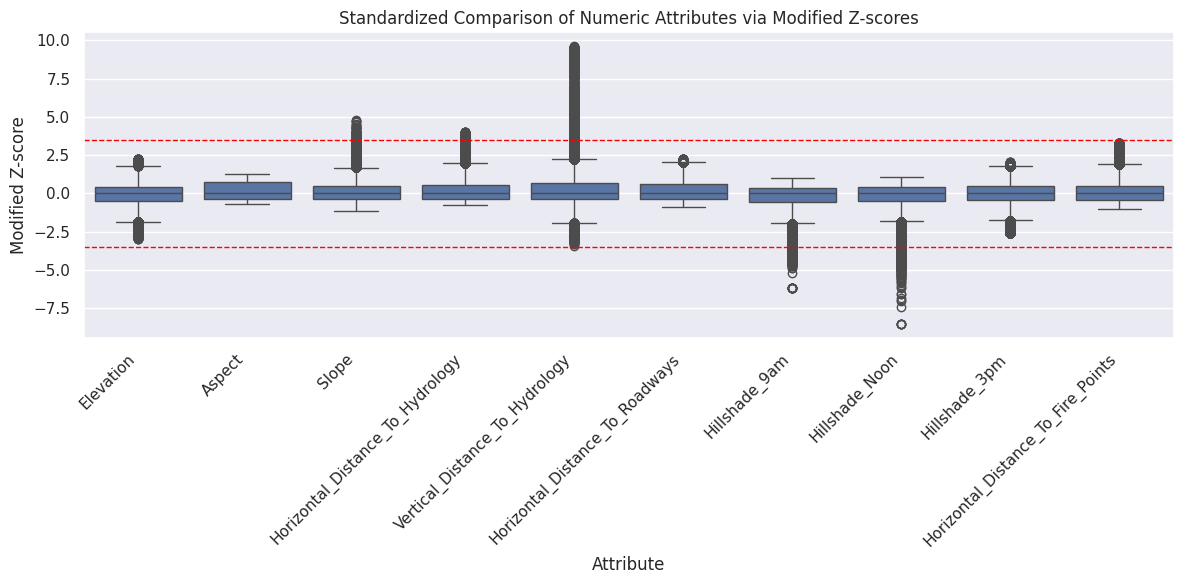

In [8]:
from scipy import stats

# modified z-score: robust standardization using median and MAD instead of
# mean/std, so heavily skewed columns don't distort the comparison
def modified_zscore(series):
    median = series.median()
    mad = stats.median_abs_deviation(series, scale='normal')
    return 0.6745 * (series - median) / mad

modified_z_scores = df[numeric_cols].apply(modified_zscore)
# reshape to long format so all 10 attributes can go on one combined boxplot
modified_z_long = modified_z_scores.melt(var_name='Attribute', value_name='Modified Z-score')

plt.figure(figsize=(12, 6))
sns.boxplot(data=modified_z_long, x='Attribute', y='Modified Z-score')
plt.title('Standardized Comparison of Numeric Attributes via Modified Z-scores')
plt.xticks(rotation=45, ha='right')
# dashed lines mark the standard |modified z| > 3.5 outlier threshold
plt.axhline(3.5, color='red', linestyle='--', linewidth=1)
plt.axhline(-3.5, color='red', linestyle='--', linewidth=1)
plt.tight_layout()
plt.show()

This standardized view tells a somewhat different story than the raw boxplots
above. `Vertical_Distance_To_Hydrology` is still clearly the most extreme
attribute, reaching a modified z-score of almost 9.6, which is consistent
with what we already found: it is the only attribute that can go negative,
so its distribution is naturally the widest relative to its own median.
What is new here is that `Hillshade_9am` and `Hillshade_Noon` show the most
extreme values on the negative side, down to about -6.2 and -8.6
respectively, something that was not obvious from the raw-unit boxplots since
those two attributes have a small absolute range (0 to 255) that visually
compressed their outliers. On the other hand, `Horizontal_Distance_To_Roadways`
and `Horizontal_Distance_To_Fire_Points`, which had some of the highest
percentages of outliers under the plain IQR rule earlier, barely cross the
threshold at all once standardized this way. This happens because the median
absolute deviation adapts to how spread out a skewed distribution already is,
so it is more forgiving toward the same kind of skew that made the IQR rule
flag so many points for those two attributes. As with the other outlier
checks in this section, we are not treating any of these as errors. We are
simply using this as one more way to see which attributes carry the most
unusual values relative to their own typical spread.

In [9]:
# Tukey's IQR rule: flag anything outside [Q1 - 1.5*IQR, Q3 + 1.5*IQR]
outlier_summary = []
for col in numeric_cols:
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    n_out = ((df[col] < lo) | (df[col] > hi)).sum()
    outlier_summary.append({
        'attribute': col, 'Q1': q1, 'Q3': q3, 'IQR': iqr,
        'lower_bound': lo, 'upper_bound': hi,
        'n_outliers': n_out, 'pct_outliers': round(n_out/len(df)*100, 2)
    })

outlier_df = pd.DataFrame(outlier_summary).set_index('attribute')
outlier_df

,Q1,Q3,IQR,lower_bound,upper_bound,n_outliers,pct_outliers
attribute,,,,,,,
Elevation,2809.0,3163.0,354.0,2278.0,3694.0,15569,2.68
Aspect,58.0,260.0,202.0,-245.0,563.0,0,0.00
Slope,9.0,18.0,9.0,-4.5,31.5,15316,2.64
Horizontal_Distance_To_Hydrology,108.0,384.0,276.0,-306.0,798.0,14557,2.51
Vertical_Distance_To_Hydrology,7.0,69.0,62.0,-86.0,162.0,31463,5.42
Horizontal_Distance_To_Roadways,1106.0,3328.0,2222.0,-2227.0,6661.0,669,0.12
Hillshade_9am,198.0,231.0,33.0,148.5,280.5,17433,3.00
Hillshade_Noon,213.0,237.0,24.0,177.0,273.0,15672,2.70
Hillshade_3pm,119.0,168.0,49.0,45.5,241.5,7832,1.35


Based on what the boxplots show,
- `Vertical_Distance_To_Hydrology` has by far the most outliers. It's the only
  column that can go negative (water can sit above or below a given cell), so
  its distribution is naturally wider and more lopsided than the others. This is not an
  error but rather just terrain.
- `Horizontal_Distance_To_Roadways` and `Horizontal_Distance_To_Fire_Points`
  both show a noticeable long tail skewed to the right. Most cells sit fairly close to a
  road or a historical fire point, but a minority are genuinely deep in remote
  wilderness.
- The three `Hillshade_*` columns are bounded between 0 and 255 by
  construction, since they're a computed illumination index. Their
  outliers are really just the extreme ends of that fixed, valid range,
  nothing unusual.
- `Slope` and `Elevation` have very few outliers, which makes sense given that
  elevation is essentially bounded by the physical terrain of these specific
  wilderness areas.

None of these look like data entry mistakes. Every flagged value is a
plausible, physically real GIS measurement, so we decide to keep all of the rows as they are.
The distance based variables would likely still benefit from a log-transform
or robust scaling before being used in anything sensitive to scale downstream,
like PCA or k-nearest neighbors.

Below, we are checking z-scores (`|z| > 3`).

In [10]:
from scipy import stats

# second outlier-detection pass: plain z-score, flag |z| > 3
zscore_summary = []
for col in numeric_cols:
    z = np.abs(stats.zscore(df[col]))
    n_out = (z > 3).sum()
    zscore_summary.append({
        'attribute': col,
        'n_outliers_zscore': n_out,
        'pct_outliers_zscore': round(n_out/len(df)*100, 2)
    })

zscore_df = pd.DataFrame(zscore_summary).set_index('attribute')
# join against the IQR results for a side-by-side comparison
zscore_df = zscore_df.join(outlier_df[['pct_outliers']].rename(columns={'pct_outliers': 'pct_outliers_iqr'}))
zscore_df

,n_outliers_zscore,pct_outliers_zscore,pct_outliers_iqr
attribute,,,
Elevation,5832,1.00,2.68
Aspect,0,0.00,0.00
Slope,4074,0.70,2.64
Horizontal_Distance_To_Hydrology,7073,1.22,2.51
Vertical_Distance_To_Hydrology,10059,1.73,5.42
Horizontal_Distance_To_Roadways,33,0.01,0.12
Hillshade_9am,7516,1.29,3.00
Hillshade_Noon,7082,1.22,2.70
Hillshade_3pm,3042,0.52,1.35


The z-score comes back noticeably more conservative than IQR across the board,
and it flags fewer rows especially on the most skewed columns. That makes sense as
IQR is based on quartiles, so it is more sensitive to the skew. On the contrary, the z-score
depends on the mean and standard deviation, which gets pulled around by that
same skew, therefore making the z-score more forgiving on lopsided distributions. Either
way, the conclusion is the same: nothing here looks like an actual data error,
just legitimately skewed and extreme, but real terrain values. Therefore, nothing
gets removed.

### 2.4 Simple statistics for the most important attributes

In [11]:
df[numeric_cols].describe()

,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points
count,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000
mean,2959.365301,155.656807,14.103704,269.428217,46.418855,2350.146611,212.146049,223.318716,142.528263,1980.291226
std,279.984734,111.913721,7.488242,212.549356,58.295232,1559.254870,26.769889,19.768697,38.274529,1324.195210
min,1859.000000,0.000000,0.000000,0.000000,-173.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2809.000000,58.000000,9.000000,108.000000,7.000000,1106.000000,198.000000,213.000000,119.000000,1024.000000
50%,2996.000000,127.000000,13.000000,218.000000,30.000000,1997.000000,218.000000,226.000000,143.000000,1710.000000
75%,3163.000000,260.000000,18.000000,384.000000,69.000000,3328.000000,231.000000,237.000000,168.000000,2550.000000
max,3858.000000,360.000000,66.000000,1397.000000,601.000000,7117.000000,254.000000,254.000000,254.000000,7173.000000


In [12]:
# median and variance for every numeric attribute
print("Median:\n", df[numeric_cols].median())
print()
print("Variance:\n", df[numeric_cols].var())

Median:
 Elevation                             2996.0
Aspect                                 127.0
Slope                                   13.0
Horizontal_Distance_To_Hydrology       218.0
Vertical_Distance_To_Hydrology          30.0
Horizontal_Distance_To_Roadways       1997.0
Hillshade_9am                          218.0
Hillshade_Noon                         226.0
Hillshade_3pm                          143.0
Horizontal_Distance_To_Fire_Points    1710.0
dtype: float64

Variance:
 Elevation                             7.839145e+04
Aspect                                1.252468e+04
Slope                                 5.607377e+01
Horizontal_Distance_To_Hydrology      4.517723e+04
Vertical_Distance_To_Hydrology        3.398334e+03
Horizontal_Distance_To_Roadways       2.431276e+06
Hillshade_9am                         7.166269e+02
Hillshade_Noon                        3.908014e+02
Hillshade_3pm                         1.464940e+03
Horizontal_Distance_To_Fire_Points    1.753493e+06
dtyp

In [13]:
# mode and range (max - min) for every numeric attribute
print("Mode:\n", df[numeric_cols].mode().iloc[0])
print()
print("Range (max - min):\n", df[numeric_cols].max() - df[numeric_cols].min())

Mode:
 Elevation                             2968
Aspect                                  45
Slope                                   11
Horizontal_Distance_To_Hydrology        30
Vertical_Distance_To_Hydrology           0
Horizontal_Distance_To_Roadways        150
Hillshade_9am                          226
Hillshade_Noon                         228
Hillshade_3pm                          143
Horizontal_Distance_To_Fire_Points     618
Name: 0, dtype: int64

Range (max - min):
 Elevation                             1999
Aspect                                 360
Slope                                   66
Horizontal_Distance_To_Hydrology      1397
Vertical_Distance_To_Hydrology         774
Horizontal_Distance_To_Roadways       7117
Hillshade_9am                          254
Hillshade_Noon                         254
Hillshade_3pm                          254
Horizontal_Distance_To_Fire_Points    7173
dtype: int64


All of these columns are stored as whole-number integers in the raw data, so every one of them technically has a
single most common value.

`Vertical_Distance_To_Hydrology`'s mode of 0 stands
out as this indicates that the single most common exact value is sitting right at water
level.

`Aspect`'s mode of 45 degrees lines up exactly with the busiest wedge
in the polar histogram: northeast, ~25,600 cells (shown in section 2.5). This is a nice
consistency check between the two views.

Range confirms what the histograms
already suggested: `Horizontal_Distance_To_Fire_Points` (7,173 m) and
`Horizontal_Distance_To_Roadways` (7,117 m) have by far the widest ranges,
while `Slope` has the narrowest at just 66 degrees.

In [14]:
# raw counts and percentages for the target class
print("Target class balance:")
print(df['cover_type_name'].value_counts())
print()
print(df['cover_type_name'].value_counts(normalize=True).round(4) * 100)

Target class balance:
cover_type_name
Lodgepole Pine       283301
Spruce/Fir           211840
Ponderosa Pine        35754
Krummholz             20510
Douglas-fir           17367
Aspen                  9493
Cottonwood/Willow      2747
Name: count, dtype: int64

cover_type_name
Lodgepole Pine       48.76
Spruce/Fir           36.46
Ponderosa Pine        6.15
Krummholz             3.53
Douglas-fir           2.99
Aspen                 1.63
Cottonwood/Willow     0.47
Name: proportion, dtype: float64


It is also worth taking a consolidated look at more than just the target's
balance on its own. Adapted from a group member's (Moinak Ghosh) exploratory
notebook: this reshapes multiple categorical columns (count and percentage
together) into one combined table instead of printing `.value_counts()`
separately for each one.

In [15]:
# Adapted from a group member's (Moinak Ghosh) exploratory notebook: combine
# count + percentage for multiple categorical columns into one long table.
# Changed here: cat_cols set to this notebook's own cover_type_name and
# wilderness_area_name columns instead of the original's cat_cols list, and
# soil_type/climatic_zone are left out here since they are already covered
# individually elsewhere (section 2.5's top-15 soil chart, section 2.8's
# zone crosstabs).
from IPython.display import display

# wilderness_area_name is not created until section 2.5, so we build it here
# too (the same mapping used there) to keep this cell self-contained
wilderness_names = {1: 'Rawah', 2: 'Neota', 3: 'Comanche Peak', 4: 'Cache la Poudre'}
df['wilderness_area_name'] = df['wilderness_area'].map(wilderness_names)

cat_cols = ['cover_type_name', 'wilderness_area_name']

balance_df = pd.concat(
    {col: df[col].value_counts() for col in cat_cols},
    names=['Column', 'Class'],
).rename('Count').to_frame().sort_index()

totals = balance_df['Count'].groupby(level='Column').transform('sum')
balance_df['Percentage'] = balance_df['Count'].div(totals).mul(100)

with pd.option_context('display.max_rows', None):
    display(balance_df.round(2))

Count  Percentage
Column               Class                                
cover_type_name      Aspen                9493        1.63
                     Cottonwood/Willow    2747        0.47
                     Douglas-fir         17367        2.99
                     Krummholz           20510        3.53
                     Lodgepole Pine     283301       48.76
                     Ponderosa Pine      35754        6.15
                     Spruce/Fir         211840       36.46
wilderness_area_name Cache la Poudre     36968        6.36
                     Comanche Peak      253364       43.61
                     Neota               29884        5.14
                     Rawah              260796       44.89

This shows the same `cover_type_name` numbers already discussed above, now
placed alongside `wilderness_area_name` in one table. Rawah (44.9%) and
Comanche Peak (43.6%) together account for nearly 89% of all cells, while
Neota, the smallest wilderness area, makes up only 5.1%. This imbalance in
area size is worth keeping in mind alongside the cover-type imbalance,
since a rare cover type that is concentrated in the smallest area (such as
Cottonwood/Willow in Cache la Poudre, confirmed in section 2.6) ends up
being an even thinner slice of the data than its overall percentage alone
would suggest.

In [16]:
# the official covtype.info doc that ships with this dataset publishes its own
# mean/std for these columns -- quick check that this extract matches
official_stats = {
    'Elevation': (2959.36, 279.98), 'Aspect': (155.65, 111.91), 'Slope': (14.10, 7.49),
    'Horizontal_Distance_To_Hydrology': (269.43, 212.55),
    'Vertical_Distance_To_Hydrology': (46.42, 58.30),
    'Horizontal_Distance_To_Roadways': (2350.15, 1559.25),
    'Hillshade_9am': (212.15, 26.77), 'Hillshade_Noon': (223.32, 19.77),
    'Hillshade_3pm': (142.53, 38.27),
    'Horizontal_Distance_To_Fire_Points': (1980.29, 1324.19)
}

for col, (official_mean, official_std) in official_stats.items():
    our_mean, our_std = df[col].mean(), df[col].std()
    print(f"{col:38s} mean: ours={our_mean:9.2f} official={official_mean:9.2f}  |  "
          f"std: ours={our_std:8.2f} official={official_std:8.2f}")

Elevation                              mean: ours=  2959.37 official=  2959.36  |  std: ours=  279.98 official=  279.98
Aspect                                 mean: ours=   155.66 official=   155.65  |  std: ours=  111.91 official=  111.91
Slope                                  mean: ours=    14.10 official=    14.10  |  std: ours=    7.49 official=    7.49
Horizontal_Distance_To_Hydrology       mean: ours=   269.43 official=   269.43  |  std: ours=  212.55 official=  212.55
Vertical_Distance_To_Hydrology         mean: ours=    46.42 official=    46.42  |  std: ours=   58.30 official=   58.30
Horizontal_Distance_To_Roadways        mean: ours=  2350.15 official=  2350.15  |  std: ours= 1559.25 official= 1559.25
Hillshade_9am                          mean: ours=   212.15 official=   212.15  |  std: ours=   26.77 official=   26.77
Hillshade_Noon                         mean: ours=   223.32 official=   223.32  |  std: ours=   19.77 official=   19.77
Hillshade_3pm                          m

To ensure that we are working with a real, complete dataset, we double check whether the mean and standard deviation we calculated matches the dataset's officially published mean and standard deviation values. As a result, the mean and standard deviation values
almost matches, with only small rounding differences. This is good
confirmation; we are not working with some altered or
subsampled version.

A few things worth noting from these statistics:
- `Elevation`: The mean is approximately 2,959 m. The median is approximately 2,996 m. The range is roughly between 1,860 m and 3,858 m.
  That is consistent with subalpine and alpine terrain in the Colorado Rockies.
  This is very likely going to turn out to be the single strongest predictor
  of cover type since tree species zoning by altitude is one of the
  well known patterns in forest ecology, which has been confirmed directly with real numbers in section 2.7.
- `Aspect`: The mean of approximately 156 degrees doesn't mean much on its own since aspect is
  circular. That is exactly the issue flagged back in section 2.2, and it gets
  addressed properly in sections 2.5 and 2.8.
- `Slope`: The median is 13 degrees. This feature's distribution is skewed to the right, with most of the terrain being gentle to
  moderate. Its long tail due to the skewness display steeper slopes up to 66 degrees.
- `Horizontal_Distance_To_Roadways`: Its median is approximately 1,997 m versus its mean of approximately 2,350 m is a
  clear sign of right skew. Most cells are moderately close to a road, but a
  minority are quite far out.
- The class balance is quite imbalanced as the Lodgepole Pine and Spruce/Fir together
  account for over 85% of the data, while Cottonwood/Willow makes up under
  0.5%. This is exactly why plain accuracy would be a misleading metric here,
  as already flagged in section 1.

### 2.5 Visualizing the most important attributes

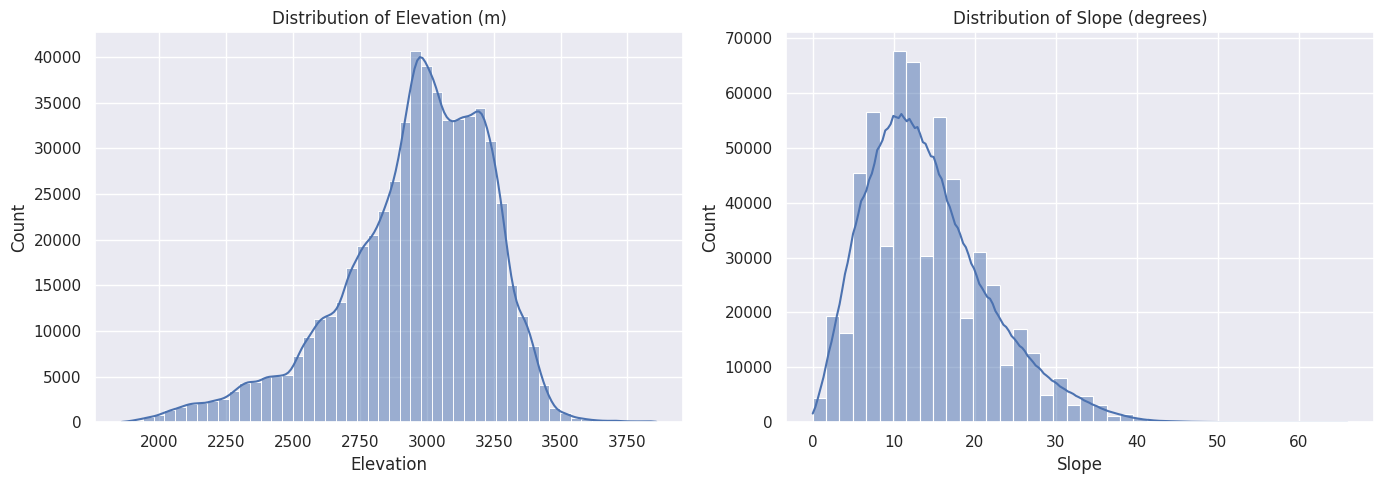

In [17]:
# histogram + KDE for the two continuous attributes Elevation and Slope
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df['Elevation'], bins=50, kde=True, ax=axes[0])
axes[0].set_title('Distribution of Elevation (m)')
sns.histplot(df['Slope'], bins=40, kde=True, ax=axes[1])
axes[1].set_title('Distribution of Slope (degrees)')
plt.tight_layout()
plt.show()

A histogram with a KDE overlay is the natural choice for both `Elevation`
and `Slope` since they are both continuous numeric attributes. `Elevation`
looks somewhat multimodal rather than a single smooth bump, which is an
early hint at the distinct "elevation bands" that different cover types
occupy, which is explored fully in section 2.7. `Slope` is skewed to the right, where the majority of the measurements are less than 20 degrees, thus indicating that most forests have a gentle
terrain.

 `Aspect` is the compass direction a slope faces. It is the direction a ball will roll downhill for example. It is stored as degrees, from 0 to 360 degrees, using standard compass
convention (0/360 degrees = north, 90 degrees = east, 180 degrees = south, and 270 degrees = west). This matters
ecologically because `Aspect` controls how much direct sunlight a slope
receives, which affects temperature and soil moisture, therefore driving
what actually grows there.

Plotting `Aspect` on a regular linear histogram creates a real problem: degrees
wrap around. For instance, 359 degrees and 1 degree are almost the same direction (only 2 degrees
apart) but would land at opposite ends of a normal x-axis, as far apart as the
chart allows. Any genuine clustering of cells facing north would get
artificially split in half and visually hidden.

Therefore, instead of plotting `Aspect` on a regular linear histogram, it is plotted on a polar histogram, which completely avoids the problems mentioned earlier. Direction goes around the circle instead of along a line: 0/360 degrees at
the top to represent north, moving clockwise through east, south, and west, the same way an
actual compass works. Additionally, the distance each wedge extends from the center of the polar histogram represents the count of cells facing that direction.

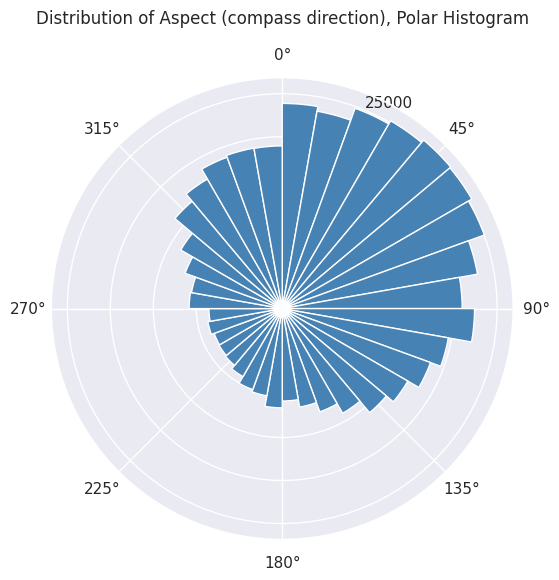

In [18]:
plt.figure(figsize=(8, 6))
# aspect is circular, so a regular linear histogram would be misleading -
# using a polar plot instead
ax = plt.subplot(111, projection='polar')
counts, bin_edges = np.histogram(np.deg2rad(df['Aspect']), bins=36, range=(0, 2*np.pi))
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
ax.bar(bin_centers, counts, width=2*np.pi/36, color='steelblue', edgecolor='white')
ax.set_theta_zero_location('N')
ax.set_theta_direction(-1)
plt.title('Distribution of Aspect (compass direction), Polar Histogram', y=1.1)
plt.show()

*Since we have not learned how to create polar histograms in class yet, we had to look online to assist us in creating a polar histogram for the `Aspect` feature. Referring to https://zetcode.com/matplotlib/polar-charts/, we utilized just the blueprint of the code (such as deciding the direction to read the polar histogram and the color the wedges should be) while making modifications to align to what we need to measure (such as how many wedges are needed for this polar histogram as well as how wide each wedge be).*

Reading the polar histogram: the wedges pointing toward NE/ENE (roughly 25-65deg) are the longest by a clear margin. The single busiest 10-degree slice is 45deg (due northeast). The wedges pointing toward SW (roughly 215-265deg) are the shortest. The quietest slice is 245deg, less than a third of the northeast peak. So the shape isn't close to a circle. It visibly bulges outward toward the top right (NE) and pinches inward toward the bottom left (SW).

This makes sense physically once we understand the geography: we are analyzing the
Colorado mountain terrain, and slopes facing north and northeast receive
less direct sunlight, so they stay cooler and retain moisture longer, which
creates better growing conditions for forests. On the contrary, slopes facing south and
southwest receive more direct sun and dry out faster, so they are more likely
to end up sparser or not forested. Since this dataset only samples cells that
are already forested, that is exactly why northeast facing cells show up more often than the southwest facing ones. This is not random measurement
noise, this is a genuine reflection of which slope orientations tend to actually
support forests in Colorado. This is also a good concrete example of why the raw mean
aspect (~156 degrees, noted back in section 2.4) was not a meaningful summary on its
own. Averaging a circular variable like this cannot capture a lopsided,
biased toward two directions pattern like the one actually present in the data.

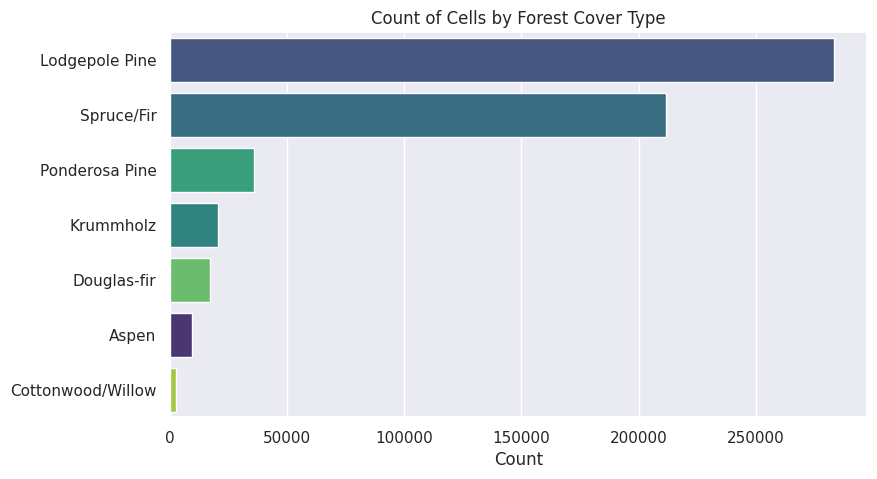

In [19]:
# bar chart of cover type counts, sorted largest to smallest
plt.figure(figsize=(9, 5))
order = df['cover_type_name'].value_counts().index
sns.countplot(data=df, y='cover_type_name', order=order, hue='cover_type_name',
              palette='viridis', legend=False)
plt.title('Count of Cells by Forest Cover Type')
plt.xlabel('Count')
plt.ylabel('')
plt.show()

We measure `Cover_Type` with a bar chart since it's a nominal
categorical variable with 7 levels and no natural numeric order. This chart
makes the class imbalance already noted in section 2.4
visually obvious: Lodgepole Pine and Spruce/Fir clearly dominate the count, while the
other five classes are comparatively small.

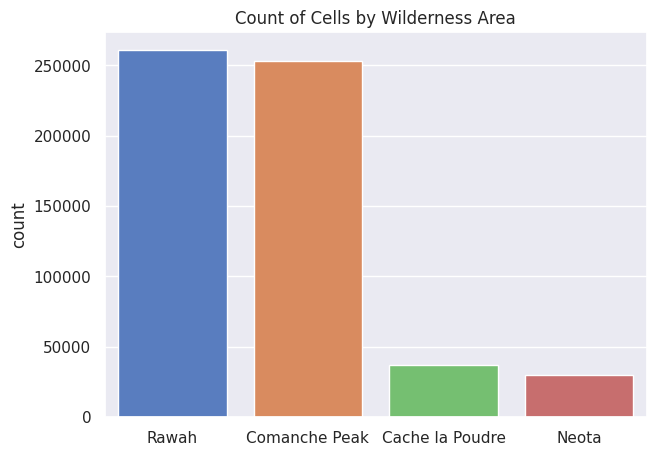

In [20]:
# map wilderness area codes to readable names, then bar chart the counts
plt.figure(figsize=(7, 5))
wilderness_names = {1: 'Rawah', 2: 'Neota', 3: 'Comanche Peak', 4: 'Cache la Poudre'}
df['wilderness_area_name'] = df['wilderness_area'].map(wilderness_names)
sns.countplot(data=df, x='wilderness_area_name', hue='wilderness_area_name',
              palette='muted', legend=False,
              order=df['wilderness_area_name'].value_counts().index)
plt.title('Count of Cells by Wilderness Area')
plt.xlabel('')
plt.show()

There are only 4 categories in the `wilderness_area_name` feature, so plotting them on a simple bar chart is enough. Rawah and Comanche
Peak clearly dominate the sample in terms of cell count, while Neota, the
smallest of the four designated wilderness areas, barely registers by
comparison. There is a correlation between wilderness area and forest cover type as Rawah and Comanche Peak have lodgepole pine trees as the primary major tree species, in which most of the forest cover type in the Roosevelt National Forest of northern Colorado is lodgepole pine trees, according to the dataset information section of the UCI dataset repository we extracted the raw dataset from.

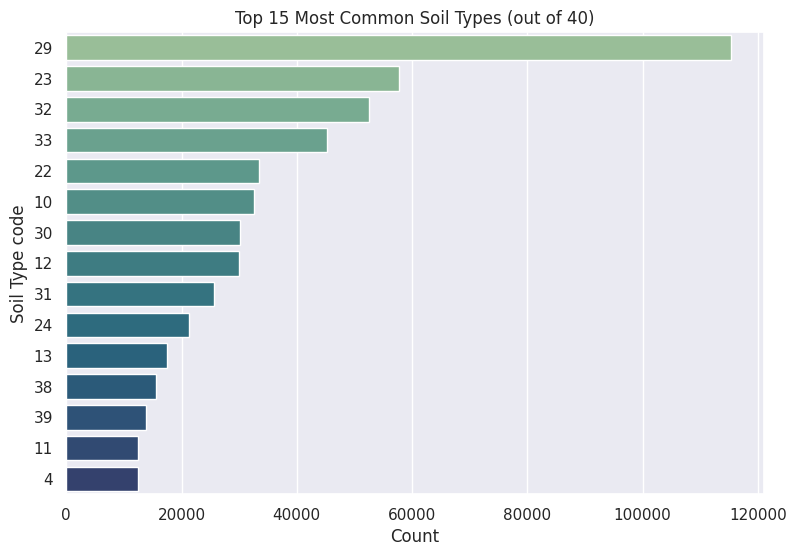

In [21]:
# bar chart of the 15 most common soil types (out of 40 total)
plt.figure(figsize=(9, 6))
top_soil = df['soil_type'].value_counts().head(15)
sns.barplot(x=top_soil.values, y=[str(s) for s in top_soil.index], hue=[str(s) for s in top_soil.index],
            palette='crest', legend=False, order=[str(s) for s in top_soil.index])
plt.xlabel('Count')
plt.ylabel('Soil Type code')
plt.title('Top 15 Most Common Soil Types (out of 40)')
plt.show()

Another bar chart has been created to categorize soil by its `soil_type` as `soil_type` is nominal categorical. However, since there are 40 different codes of `soil_type` in this dataset and plotting all of that would be extremely unreadable, we decided to restrict that to just the top 15 of 40 possible codes. We notice that `soil_type` 29 alone accounts for roughly 115,000 cells, about 20%
of the entire dataset, massively outnumbering every other individual code.
After that, the counts drop off quickly. This is the visual confirmation of
the "some soil types are extremely rare" finding from section 2.3, and it is
part of the reasoning behind grouping the 40 raw soil codes into
`climatic_zone`/`geologic_zone` in section 2.8, rather than treating all 40 as
equally meaningful, independent categories.

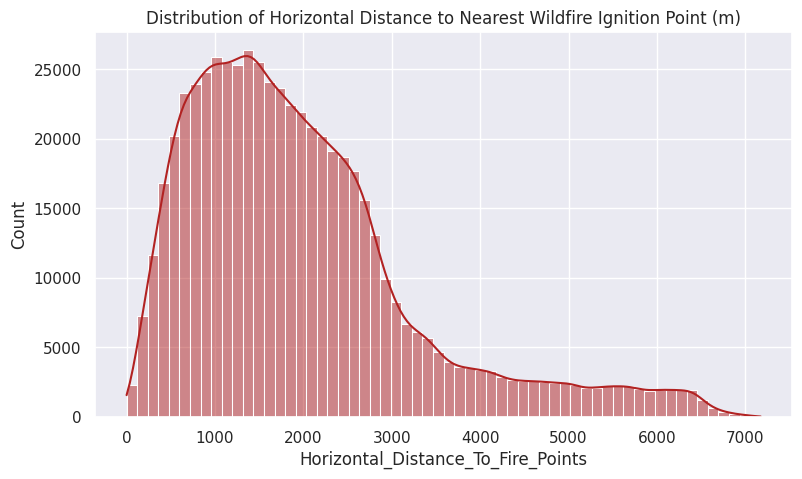

In [22]:
# histogram of distance to nearest wildfire ignition point
plt.figure(figsize=(9, 5))
sns.histplot(df['Horizontal_Distance_To_Fire_Points'], bins=60, kde=True, color='firebrick')
plt.title('Distribution of Horizontal Distance to Nearest Wildfire Ignition Point (m)')
plt.show()

This distribution of horizontal distance to the nearest wildfire ignition point is skewed to the right: most cells sit within a few thousand
meters of a historical wildfire ignition point, with a long tail of cells
that are genuinely much farther away. This could be relevant context for any
wildfire related forest management use case built on top of this data.

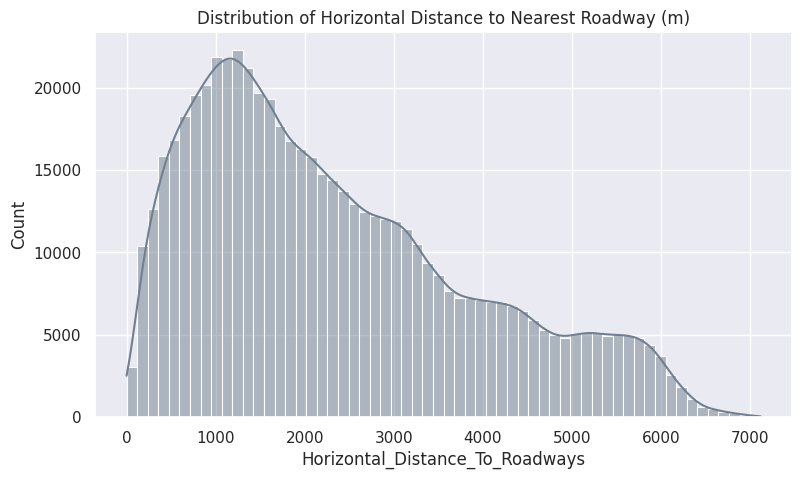

In [23]:
# histogram of distance to nearest roadway
plt.figure(figsize=(9, 5))
sns.histplot(df['Horizontal_Distance_To_Roadways'], bins=60, kde=True, color='slategray')
plt.title('Distribution of Horizontal Distance to Nearest Roadway (m)')
plt.show()

This distribution follows the same shape story as the fire point distance chart above
(the median is ~1,997 m, and the mean is ~2,350 m). Most cells sit within a couple thousand
meters of a road, with a long right tail of genuinely remote cells extending
out past 5,000 to 7,000 meters. This is worth comparing directly against the
fire points histogram since the two turn out to be moderately correlated, which is later confirmed in section 2.6. This makes sense as both variables are
tracking the same underlying signal of "how developed or accessible is this cell".

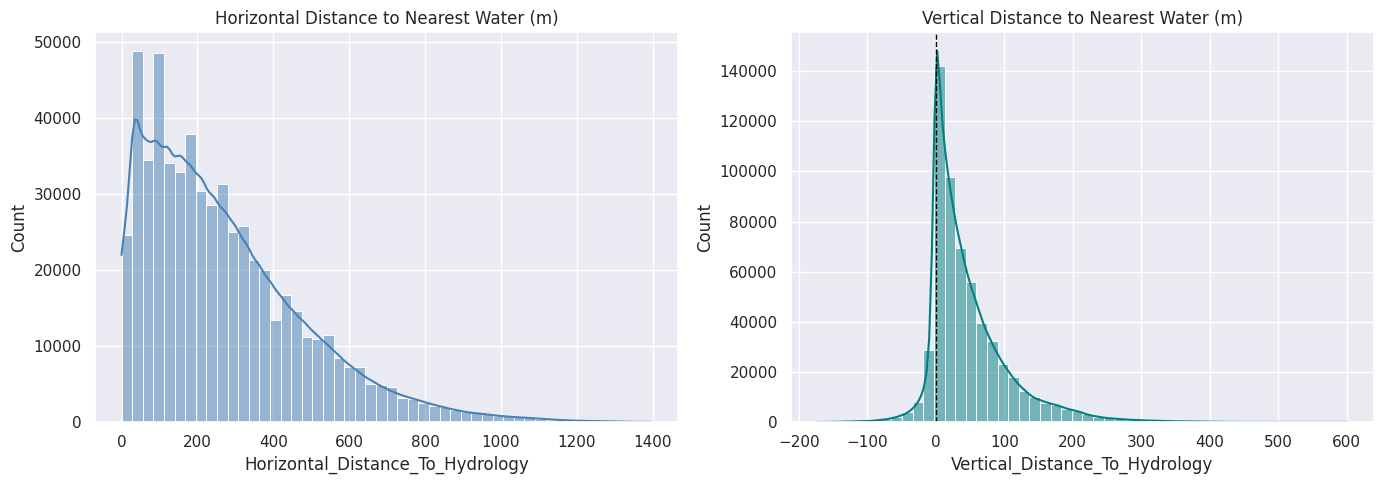

In [24]:
# paired histogram: horizontal and vertical distance to water
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df['Horizontal_Distance_To_Hydrology'], bins=50, kde=True, ax=axes[0], color='steelblue')
axes[0].set_title('Horizontal Distance to Nearest Water (m)')
sns.histplot(df['Vertical_Distance_To_Hydrology'], bins=50, kde=True, ax=axes[1], color='teal')
axes[1].set_title('Vertical Distance to Nearest Water (m)')
axes[1].axvline(0, color='black', linestyle='--', linewidth=1)  # mark zero to show the negative-vertical-distance cells
plt.tight_layout()
plt.show()

To analyze `Horizontal_Distance_To_Hydrology` and `Vertical_Distance_To_Hydrology`, we created a paired histogram again since these two distance variables are the natural
counterpart to each other, the same logic used for the elevation and slope pair
earlier. The `Horizontal_Distance_To_Hydrology` is skewed to the right and always
positive, with a median around 218 meters. Interestingly, the `Vertical_Distance_To_Hydrology` has its center slightly above zero (its median is 30 meters, indicating that
water is usually a bit below the cell), but about 9.5% of cells actually have
a *negative* vertical distance, meaning the nearest water source sits higher
up than the cell itself. A dashed line was added at zero specifically to make
that split visible. This is exactly why `Vertical_Distance_To_Hydrology`
showed up with the most flagged by IQR outliers back in section 2.3. It is not an
error; it's genuinely a two-sided distribution that any method assuming
everything is not negative would flag as unusual.

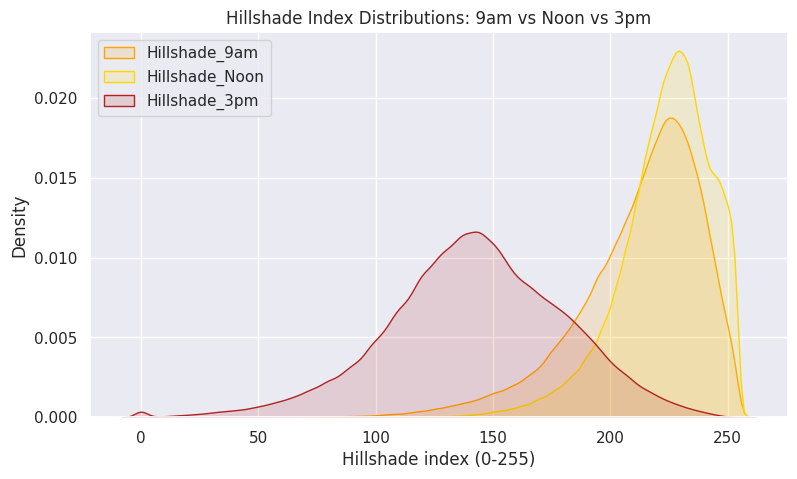

In [25]:
# overlay all three hillshade columns as KDEs for a direct shape comparison
plt.figure(figsize=(9, 5))
for col, color in zip(['Hillshade_9am', 'Hillshade_Noon', 'Hillshade_3pm'], ['orange', 'gold', 'firebrick']):
    sns.kdeplot(df[col], label=col, color=color, fill=True, alpha=0.15)
plt.xlabel('Hillshade index (0-255)')
plt.title('Hillshade Index Distributions: 9am vs Noon vs 3pm')
plt.legend()
plt.show()

All three hillshade columns are overlaid on one plot instead of drawn as
three separate charts since we want to compare their shapes
directly. `Hillshade_Noon` forms the tallest, narrowest peak, sitting highest
around a value of 223. This makes sense since midday sunlight is the most
consistent across different slope orientations, so there is less cell to cell
variation. On the contrary, `Hillshade_9am` (mean of ~212) and `Hillshade_3pm` (mean of ~143, which is
noticeably lower and more spread out) differ from each other quite a bit, which previews the strong negative correlation between the two, which has been
confirmed in section 2.6. A slope oriented to catch a lot of morning light is not usually the same slope catching a lot of afternoon light.

### 2.6 Relationships between attributes

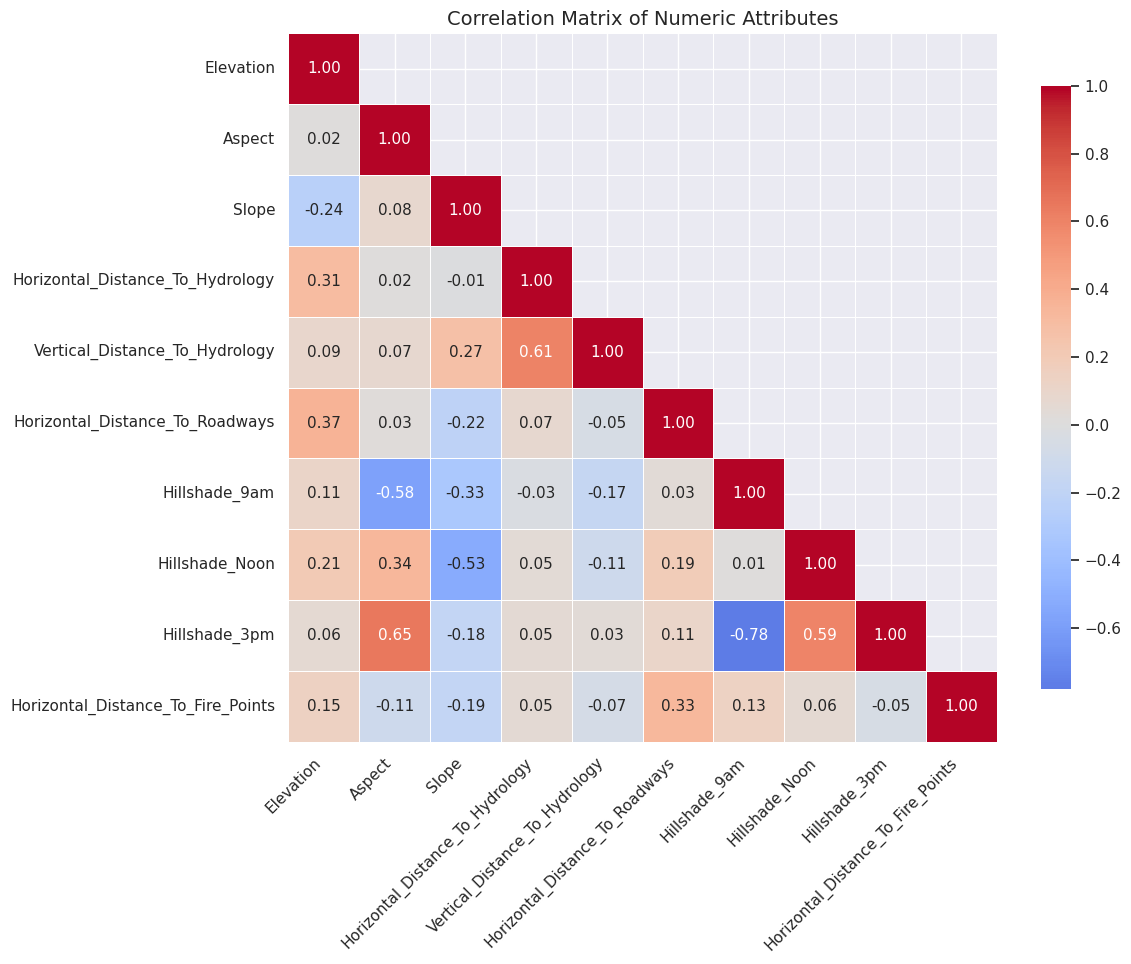

In [26]:
# correlation matrix of the 10 numeric attributes, lower triangle only
corr = df[numeric_cols].corr()

plt.figure(figsize=(12, 10))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)  # hide the redundant upper triangle
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True,
            annot_kws={'size': 11}, linewidths=0.6, linecolor='white', cbar_kws={'shrink': 0.8})
plt.title('Correlation Matrix of Numeric Attributes', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

A few things stand out (the idea to specifically check pairs above 0.5 was
prompted by a public EDA write-up on this dataset found via web search; the
actual correlation matrix and every number below is computed fresh from this
data, not copied):
- `Hillshade_9am` / `Hillshade_3pm` has a strong, negative correlation of -0.78 due to opposite sun exposure.
- `Hillshade_Noon` / `Hillshade_3pm` has a clear, positive correlation of 0.59, yet
  `Hillshade_Noon` / `Hillshade_9am` almost has zero correlation (0.01). At first glance, it might not look
  symmetric. Part of this is
  explainable as at 9 am and 3 pm, the sun sits low in the sky, off to one side
  (east in the morning, west in the afternoon). Therefore, the direction a slope faces
  makes a big difference in how much light it gets: an east-facing slope
  catches the morning sun directly, while a west-facing slope is largely
  shaded from it, and the reverse occurs in the afternoon. That is exactly why `Hillshade_9am`
  and `Hillshade_3pm` end up negatively correlated (-0.78). This causes the `Aspect` to flip, which one time frame benefits. At
  noon, the sun sits much closer to overhead, so it lights every aspect more
  evenly, which is why `Hillshade_Noon` doesn't get pulled into that same
  push-pull pattern the way `Hillshade_9am` and `Hillshade_3pm` are pulled against each other. Despite this explanation, what is not fully explained here is why `Hillshade_Noon` specifically
  leans toward correlating with the afternoon reading rather than the
  morning one. That asymmetry is real in the numbers, but we would need a closer
  look at the sun's exact path on the specific date these hillshade values
  were calculated for (the summer solstice, per the dataset documentation) to
  say why precisely.
- Both `Aspect` / `Hillshade_3pm` and `Aspect` / `Hillshade_9am` have a moderately, strong correlation of 0.65 and -0.58 respectively as aspect
  directly drives the time of day sun exposure occurs at.
- `Horizontal_` / `Vertical_Distance_To_Hydrology` has a moderately, strong correlation of 0.61 as the larger the horizontal distance to hydrology, the larger the vertical distance to hydrology.
- `Horizontal_Distance_To_Roadways` / `Horizontal_Distance_To_Fire_Points` has a moderately, positive correlation of 0.33, thus indicating that both distances track accessibility.
- `Elevation` has a weak correlation with all the other features listed in this correlation matrix; mostly independent
  signal (importance of this is explained in section 2.7).

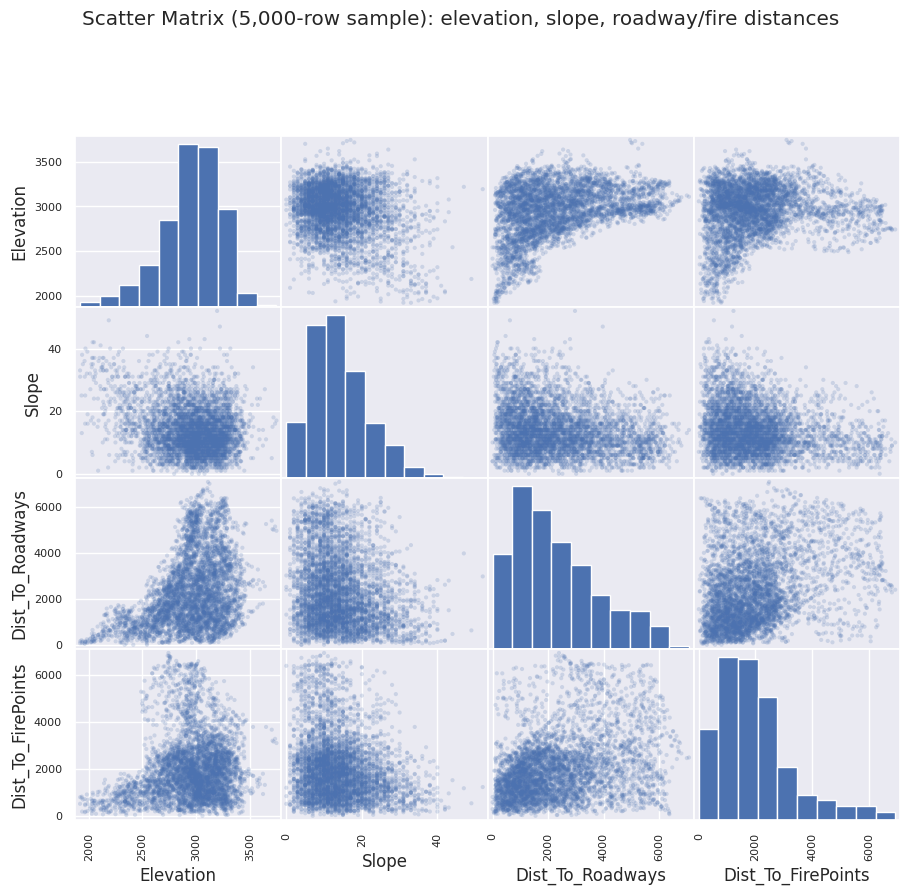

In [27]:
from pandas.plotting import scatter_matrix
# sampling for the scatter matrix -- plotting all 581k points directly would be
# slow and just look like a solid block of ink
sample_for_plot = df.sample(n=5000, random_state=42)

# the real column names are long enough that they overlap on the plot axes,
# so using short aliases just for this chart's labels
plot_cols = ['Elevation', 'Slope', 'Horizontal_Distance_To_Roadways', 'Horizontal_Distance_To_Fire_Points']
short_names = {'Elevation': 'Elevation', 'Slope': 'Slope',
               'Horizontal_Distance_To_Roadways': 'Dist_To_Roadways',
               'Horizontal_Distance_To_Fire_Points': 'Dist_To_FirePoints'}
plot_df = sample_for_plot[plot_cols].rename(columns=short_names)

axes = scatter_matrix(plot_df, figsize=(11, 9), diagonal='hist', alpha=0.2)
plt.suptitle('Scatter Matrix (5,000-row sample): elevation, slope, roadway/fire distances', y=1.02)
plt.subplots_adjust(left=0.15, bottom=0.12)
plt.show()

This matches what the heatmap already showed: there is no strong linear relationship
between `Elevation` and `Slope` as well as with either of the two distance variables. There is
a mild, negative trend visible between `Elevation` and `Dist_To_Roadways`,
where higher elevation cells tend to sit a bit farther from roads on average,
which is reasonable, given that road building is generally easier at lower
elevations.

Note that the scatter matrix above only used a 5,000-row sample for speed and
legibility, so it is worth checking again the elevation/roadway relationship
against the actual full dataset rather than relying on a sample. A hexbin
plot handles all 581k points comfortably, whereas a regular scatter plot at
that scale would just render as a solid block of overlapping dots.

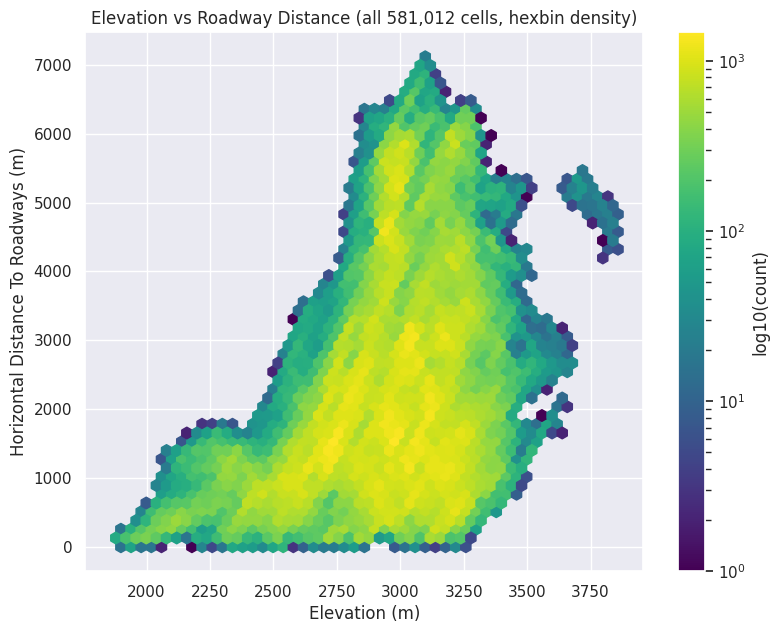

In [28]:
# hexbin density plot on the full 581k rows (a scatter plot would just be
# a solid block of overlapping points at this scale)
plt.figure(figsize=(9, 7))
hb = plt.hexbin(df['Elevation'], df['Horizontal_Distance_To_Roadways'],
                 gridsize=50, cmap='viridis', mincnt=1, bins='log')
plt.colorbar(hb, label='log10(count)')
plt.xlabel('Elevation (m)')
plt.ylabel('Horizontal Distance To Roadways (m)')
plt.title('Elevation vs Roadway Distance (all 581,012 cells, hexbin density)')
plt.show()

Based on the hexbin plot, the result turns out to be more nuanced than what the simple +0.37 correlation value
suggests. It isn't a straightforward "higher elevation means farther from
roads" trend. The full dataset density actually forms a shape closer to a wide
arrowhead. Below about 2,300 m, the spread is tight and mostly close to roads
(this is Cache la Poudre, the lowest and most accessible of the four
wilderness areas). From there up to roughly 3,000-3,100 m, the spread widens
dramatically, extending all the way out to 6,000-7,000 m. That is the large
middle elevation range covering Rawah, Comanche Peak, and Neota, where the
wilderness areas are big enough that some cells sit right at the edge near a
road, while others are deep in roadless interior. Then past about 3,300 m, the
spread narrows back in again, since the highest peaks cover a much smaller
total area, leaving less room to be very far from anything. The sample scatter matrix that we created earlier only really captured the "generally
widens with elevation" part of this pattern, whereas the hexbin plot displaying the full dataset reveals the
narrowing at the very top, which a 5,000-row sample was simply too sparse
at those elevations to make visible.

In [29]:
# cover-type composition within each wilderness area (rows sum to 100%)
soil_wild_ct = pd.crosstab(df['wilderness_area_name'], df['cover_type_name'], normalize='index') * 100
soil_wild_ct.round(1)

cover_type_name,Aspen,Cottonwood/Willow,Douglas-fir,Krummholz,Lodgepole Pine,Ponderosa Pine,Spruce/Fir
wilderness_area_name,,,,,,,
Cache la Poudre,0.0,7.4,26.3,0.0,8.2,58.0,0.0
Comanche Peak,2.3,0.0,3.0,5.2,49.4,5.6,34.5
Neota,0.0,0.0,0.0,7.7,30.1,0.0,62.2
Rawah,1.4,0.0,0.0,2.0,56.1,0.0,40.5


This table dives into a bit more detail than the horizontal bar chart counting the number of trees per forest cover type (see section 2.5) as it displays the cover-type composition within each wilderness area (rows add up to 100%). We still note that lodgepole pine and spruce/fir trees make up the majority of forest cover types within all the wilderness areas. However, with the percentage breakdown, it is interesting to see that both forest cover types barely make up Cache la Poudre: 8.2% of lodgepole pine and 0.0% of spruce/fir trees compared to the percentages of other tree types.

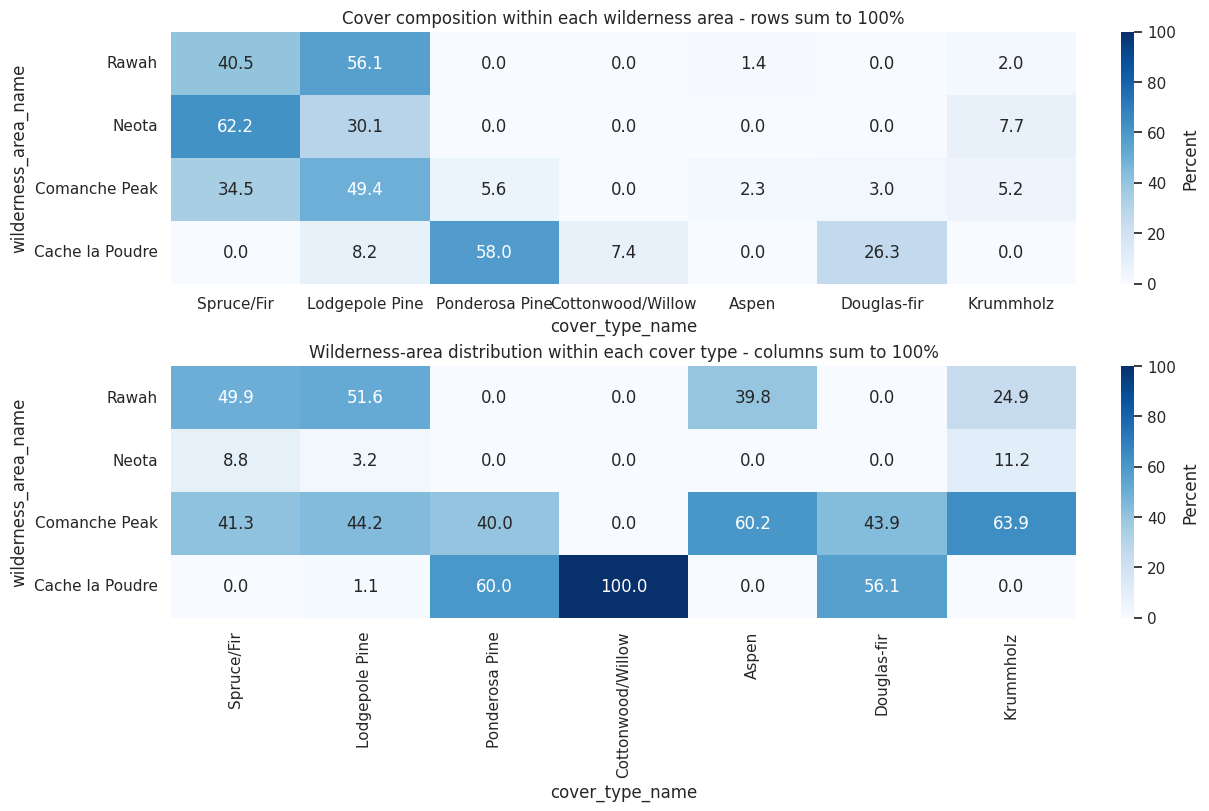

In [30]:
# Adapted from a group member's (Moinak Ghosh) exploratory notebook: builds
# both directions of the crosstab and renders as heatmaps. Changed here:
# uses this notebook's own wilderness_area_name/cover_type_name columns and
# cover_type_names/wilderness_names dicts instead of the original's
# ELU_-based Wilderness/Soil/Cover columns and cover_names dict.
cover_order = list(cover_type_names.values())
wilderness_order = list(wilderness_names.values())

area_counts = pd.crosstab(df['wilderness_area_name'], df['cover_type_name']).reindex(
    index=wilderness_order, columns=cover_order, fill_value=0
)
area_composition = area_counts.div(area_counts.sum(axis=1), axis=0) * 100
cover_distribution = area_counts.div(area_counts.sum(axis=0), axis=1) * 100

fig, axes = plt.subplots(2, 1, figsize=(12, 8), constrained_layout=True)
for ax, table, title in zip(
    axes,
    [area_composition, cover_distribution],
    ['Cover composition within each wilderness area - rows sum to 100%',
     'Wilderness-area distribution within each cover type - columns sum to 100%'],
):
    sns.heatmap(table, annot=True, fmt='.1f', cmap='Blues', vmin=0, vmax=100,
                cbar_kws={'label': 'Percent'}, ax=ax)
    ax.set_title(title)
plt.show()

Although the top panel of the heatmaps displays the same information as the table shown earlier, the top panel is easier to
scan visually. The bottom panel of the heatmaps is the new piece: reading down the
Krummholz column, 63.9% of all Krummholz trees are in Comanche Peak and
24.9% in Rawah, while none at all in Cache la Poudre. Reading down
Cottonwood/Willow tells an even more extreme story: 100% of it comes from
Cache la Poudre alone, while none from any of the other three wilderness areas. This view
answers a different question than the top panel: rather than "what does this
wilderness area mostly contain," but "where would you actually go to find
this specific cover type?" Both are useful and can tell different stories
since a wilderness area can be small in total (like Neota) but still
dominate one particular cover type's makeup, or a cover type can be
essentially exclusive to one single area, the way Cottonwood/Willow is here.

Overall, the cover type mix clearly differs quite a bit by wilderness area. Krummholz
(the stunted, high alpine tree type), for example, is essentially absent from
the lower elevation wilderness areas but shows up meaningfully in the higher
ones. Given how different the cover type composition already looks across
areas, it is worth checking directly whether the wilderness areas themselves
also differ systematically in elevation. If they do, that would explain a
large part of the cover type split seen above.

In [31]:
df.groupby('wilderness_area_name')['Elevation'].mean().sort_values(ascending=False)

,Elevation
wilderness_area_name,
Neota,3245.727814
Rawah,3000.267286
Comanche Peak,2980.554471
Cache la Poudre,2294.106038


After computing the elevation mean for each wilderness area, it has been confirmed that wilderness areas differ systematically in elevation, and these differences are substantial. Neota averages the highest
elevation at roughly 3,246 m, follow by Rawah and Comanche Peak sitting in the middle at
about 3,000 m and 2,981 m respectively, follow by Cache la Poudre sitting considerably
lower than the rest at around 2,294 m. This lines up exactly with what the
dataset's own documentation predicts: the documents describe Neota as having the
highest mean elevation, Rawah and Comanche Peak as lower, and Cache la Poudre
as the lowest of the four as well as separately predict that Cache la Poudre would
lean toward Ponderosa Pine, Douglas-fir, and Cottonwood/Willow, while
Rawah/Comanche Peak would lean toward Lodgepole Pine, Spruce/Fir, and Aspen,
and Neota toward Spruce/Fir. That matches the cover type crosstab from above
almost exactly and sets up the relationship between elevation and cover type explored in
depth next.

### 2.7 Relationships between features and the target (`Cover_Type`)

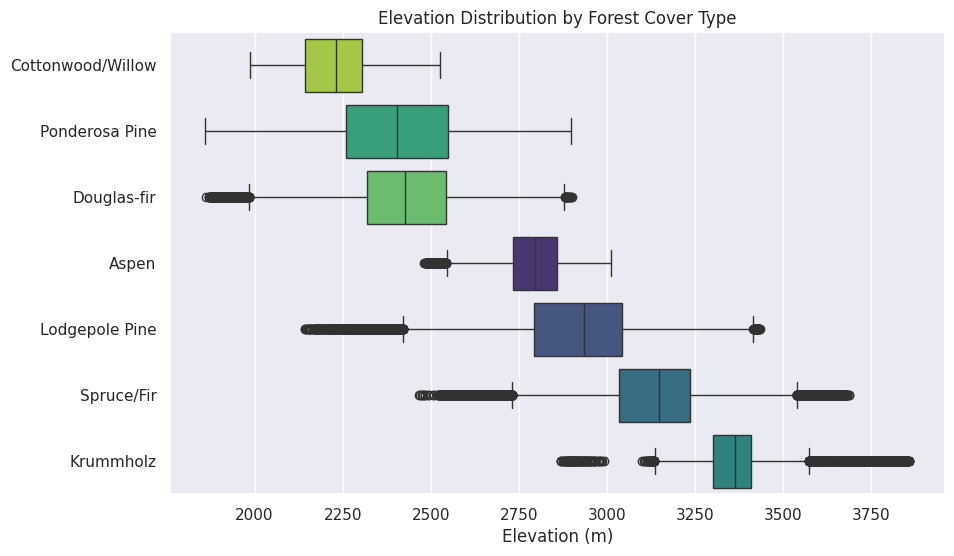

In [32]:
# boxplot of elevation by cover type, ordered by median elevation
plt.figure(figsize=(10, 6))
order = df.groupby('cover_type_name')['Elevation'].median().sort_values().index
sns.boxplot(data=df, x='Elevation', y='cover_type_name', order=order,
            hue='cover_type_name', palette='viridis', legend=False)
plt.title('Elevation Distribution by Forest Cover Type')
plt.xlabel('Elevation (m)')
plt.ylabel('')
plt.show()

The elevation distribution by forest cover type turns out to be the strongest relationship in the entire dataset.
Cover types line up almost perfectly by elevation band in a clean gradient:
Cottonwood/Willow sits at the very bottom, Ponderosa Pine and Douglas-fir
occupy the middle to low range, Lodgepole Pine and Aspen sit in the middle, and
Spruce/Fir, and especially Krummholz, dominate the highest elevations. This
matches the textbook subalpine forest ecology exactly. Krummholz literally refers
to the stunted, wind shaped trees found right at the treeline. Elevation on
its own would likely do a fairly good job of classifying cover type even
without any other attribute.

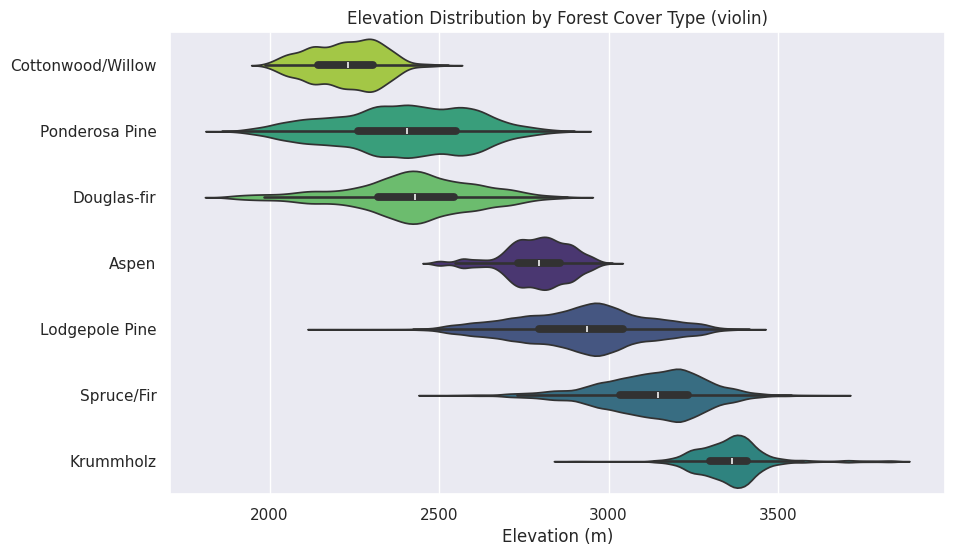

In [33]:
# same data as the boxplot above, as a violin plot to show distribution shape
plt.figure(figsize=(10, 6))
sns.violinplot(data=df, x='Elevation', y='cover_type_name', order=order,
                hue='cover_type_name', palette='viridis', legend=False)
plt.title('Elevation Distribution by Forest Cover Type (violin)')
plt.xlabel('Elevation (m)')
plt.ylabel('')
plt.show()

This is the same underlying data as the boxplot above but just rendered as a violin plot
instead, which shows the actual shape of each distribution rather than just
the quartiles and whiskers. It is worth showing both because Ponderosa Pine
is clearly bimodal in a way the boxplot alone completely hides. The boxplot
just draws one box for Ponderosa Pine, but the violin plot makes it obvious
there are actually two separate elevation clusters, one centered around
2,275 m and another around 2,575 m. The reason for this is because
Ponderosa Pine occurs in two different wilderness areas at two distinctly
different elevations (Cache la Poudre, which sits lower overall, and Comanche
Peak, which sits higher), and lumping both areas into one boxplot conceals
that split entirely.

The next chart will show ECDF plots. For a variable $x$, the empirical cumulative distribution function at
some value $t$ is simply the fraction of all observations that are less than
or equal to $t$:

$$F(t) = \frac{\text{number of observations} \le t}{n}$$

So instead of showing "how many points fall into this bin," the way a
histogram does, an ECDF shows "what fraction of the data sits at or below
this point." The curve always starts at 0, always ends at 1, and is always
never decreasing (reading left to right, it can only go up or stay flat, never
down). Comparing curves from different groups at any given x-value tells us
directly what fraction of each group falls below that point. For example, if
the Lodgepole Pine curve reads 0.5 at 2,935 m, that means exactly 50% of
Lodgepole Pine cells sit at or below 2,935 m in elevation.

Applying that here is another way to look at the same
relationship between elevation and cover type that we have already explored with the boxplot and
violin plot earlier. The ECDF view is especially useful for spotting precisely
where two classes' distributions overlap or cross, which is harder to judge
just by eyeballing where two boxes or violins happen to look close together.

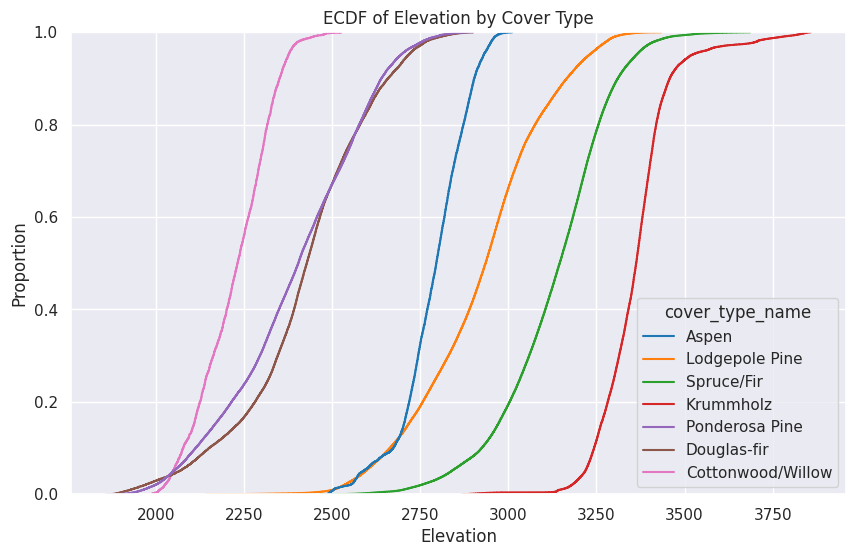

In [34]:
# ECDF of elevation, one curve per cover type
plt.figure(figsize=(10, 6))
sns.ecdfplot(data=df, x='Elevation', hue='cover_type_name', palette='tab10')
plt.title('ECDF of Elevation by Cover Type')
plt.show()

This actually surfaces something the boxplot and violin plot didn't make as
clear. It isn't only Lodgepole Pine and Spruce/Fir that sit close together.
Ponderosa Pine and Douglas-fir sit almost exactly on top of each other too
(medians of 2,404 m versus 2,428 m, with their 25th and 75th percentile ranges
overlapping almost completely), even more tight than the overlap between
Lodgepole Pine and Spruce/Fir noted above. That is a bit surprising, given that
Douglas-fir was one of the three classes flagged as hard to separate in the
PCA, LDA, and parallel coordinates work in section 3, while Ponderosa Pine
wasn't included in that group. It makes sense once we think it through
though: elevation alone puts Ponderosa Pine and Douglas-fir in the same
range, so whatever is actually separating them in a real classifier must be
coming from other attributes instead, like roadway distance, wilderness
area, or soil type, rather than from elevation. A useful reminder that "hard
to separate overall" and "hard to separate on this one specific attribute"
aren't always the same set of classes.

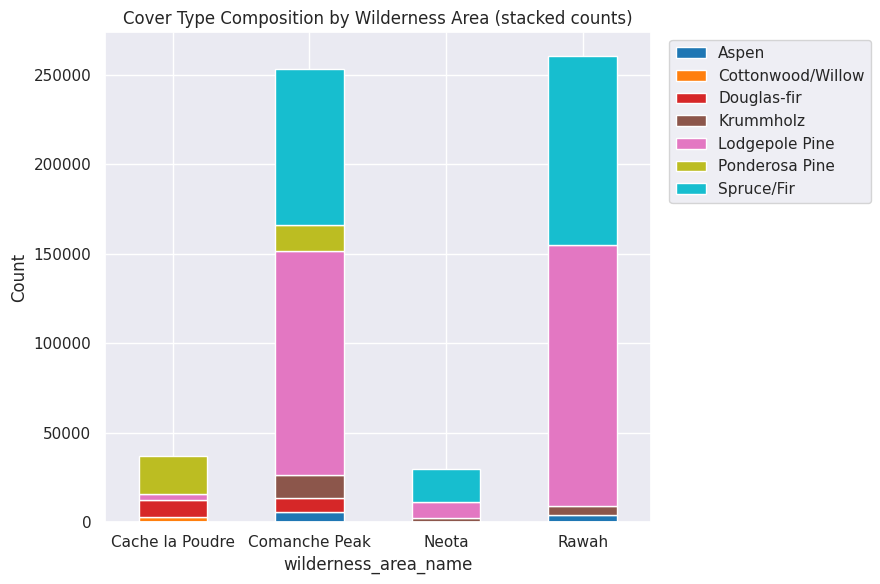

In [35]:
# stacked bar chart: cover-type counts within each wilderness area
ct = pd.crosstab(df['wilderness_area_name'], df['cover_type_name'])
ct.plot(kind='bar', stacked=True, figsize=(9, 6), colormap='tab10')
plt.title('Cover Type Composition by Wilderness Area (stacked counts)')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

This stacked bar chart confirms the crosstab from section 2.6 visually. Each wilderness area
clearly has its own distinct cover type signature, which means
`wilderness_area` by itself, even without any numeric terrain data attached,
carries real predictive information about cover type.

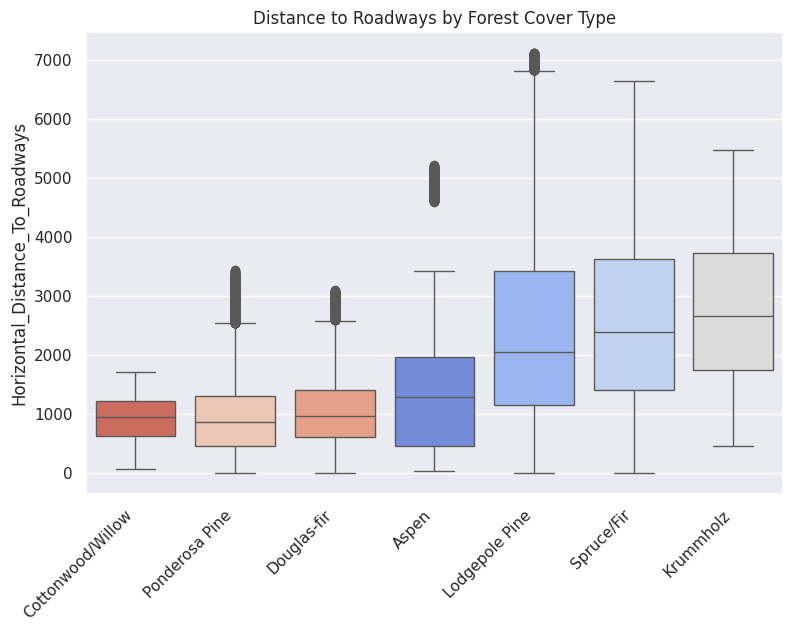

In [36]:
# roadway distance by cover type, same elevation-based ordering as above
plt.figure(figsize=(9, 6))
sns.boxplot(data=df, x='cover_type_name', y='Horizontal_Distance_To_Roadways',
            hue='cover_type_name', palette='coolwarm', legend=False,
            order=order)
plt.xticks(rotation=45, ha='right')
plt.title('Distance to Roadways by Forest Cover Type')
plt.xlabel('')
plt.show()

Krummholz and Spruce/Fir, the two highest elevation cover types, also tend
to sit farthest from roads based on the boxplots. This tracks with the general pattern of roads
following lower, more accessible terrain rather than following higher terrain. Essentially, `Elevation` and
`Horizontal_Distance_To_Roadways` are picking up a lot of the same underlying
"remoteness" signal here, which was already hinted at in the hexbin plot back
in section 2.6.

In [37]:
# how many distinct soil types each cover type appears on
soil_diversity = df.groupby('cover_type_name')['soil_type'].nunique().sort_values(ascending=False)
print(soil_diversity)

cover_type_name
Lodgepole Pine       35
Spruce/Fir           31
Aspen                20
Krummholz            20
Douglas-fir          20
Ponderosa Pine       15
Cottonwood/Willow    11
Name: soil_type, dtype: int64


The two dominant cover types, Lodgepole Pine and Spruce/Fir, show up across
the widest range of distinct soil types, while the rarer cover types, such Cottonwood/Willow and Ponderosa Pine, are concentrated on comparatively few soils. This
could simply be a byproduct of those classes being rarer overall, meaning
there is naturally less opportunity to observe them across many different soil
types, but it might also reflect genuinely narrower soil requirements for
those particular species.

One more relationship that is worth checking, using the same technique of binning a
continuous variable into ranges before tabulating is binning `Elevation`
into discrete bands and looking at how the `Cover_Type` composition changes
within each one.

In [38]:
# bin elevation into 5 bands and cross-tabulate against cover type
df['elevation_band'] = pd.cut(df['Elevation'],
                                bins=[1800, 2300, 2600, 2900, 3200, 3900],
                                labels=['<2300m', '2300-2600m', '2600-2900m', '2900-3200m', '3200m+'])

elev_cover_ct = pd.crosstab(df['elevation_band'], df['cover_type_name'], normalize='index') * 100
elev_cover_ct.round(1)

cover_type_name,Aspen,Cottonwood/Willow,Douglas-fir,Krummholz,Lodgepole Pine,Ponderosa Pine,Spruce/Fir
elevation_band,,,,,,,
<2300m,0.0,11.8,22.6,0.0,1.5,64.2,0.0
2300-2600m,1.2,1.6,22.7,0.0,32.5,41.0,1.1
2600-2900m,5.7,0.0,2.1,0.0,75.6,4.2,12.3
2900-3200m,0.4,0.0,0.0,0.3,54.2,0.0,45.2
3200m+,0.0,0.0,0.0,17.4,17.3,0.0,65.3


This tells the same story as the elevation boxplot from section 2.7, just
viewed from a different angle. Below 2,300 m, the composition is almost
entirely Ponderosa Pine and Douglas-fir. In the 2,300-2,900 m range, Lodgepole
Pine and Douglas-fir mix together. From 2,900-3,200 m, Lodgepole Pine and
Spruce/Fir dominate jointly, which is exactly the pair of classes that stays
hardest to tell apart all the way through the PCA/LDA work in section 3.
Above 3,200 m, the composition flips again to mostly Spruce/Fir, with
Krummholz finally appearing in meaningful numbers. Binning elevation this way
makes the overlap zone between cover types very concrete: the real "confusion
zone", in modeling terms, is roughly 2,600-3,200 m, not the entire elevation
range.

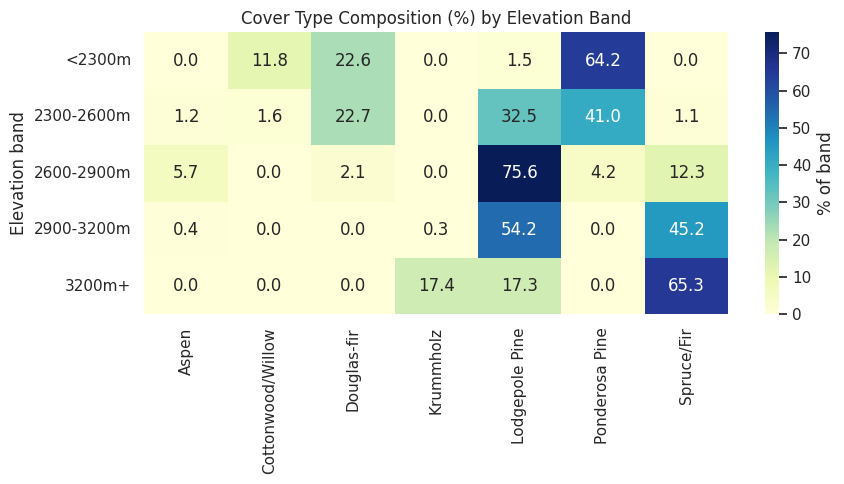

In [39]:
# same elevation-band table above, rendered as a heatmap
plt.figure(figsize=(9, 5))
sns.heatmap(elev_cover_ct, annot=True, fmt='.1f', cmap='YlGnBu', cbar_kws={'label': '% of band'})
plt.title('Cover Type Composition (%) by Elevation Band')
plt.ylabel('Elevation band')
plt.xlabel('')
plt.tight_layout()
plt.show()

Using the same table as above but rendered as a heatmap instead of raw numbers,
makes the "confusion zone" jump out immediately rather than requiring a
row by row scan of the table. The 2,600-3,200 m range is the one spot where a
single elevation band doesn't have one clearly dominant cover type: Lodgepole
Pine holds 75.6% and then 54.2% across those two bands, with Spruce/Fir
picking up most of the rest (12.3% and then 45.2%). Every other band, by
contrast, resolves to one or two cover types accounting for close to 100%
between them.

One more detailed look at the elevation/cover-type relationship is shown below.
Instead of
5 uneven custom bands across the whole dataset, these elevation bins have been converted into
fixed 100 m bands that plot the cover-type proportion as a continuous line,
which are computed separately within each wilderness area rather than pooled together.
It also explicitly blanks out any band with fewer than 100 supporting cells
(`minimum_count`), so a stretch of the line disappearing means there was not
enough data there to trust the percentage, not that the proportion dropped to
zero.

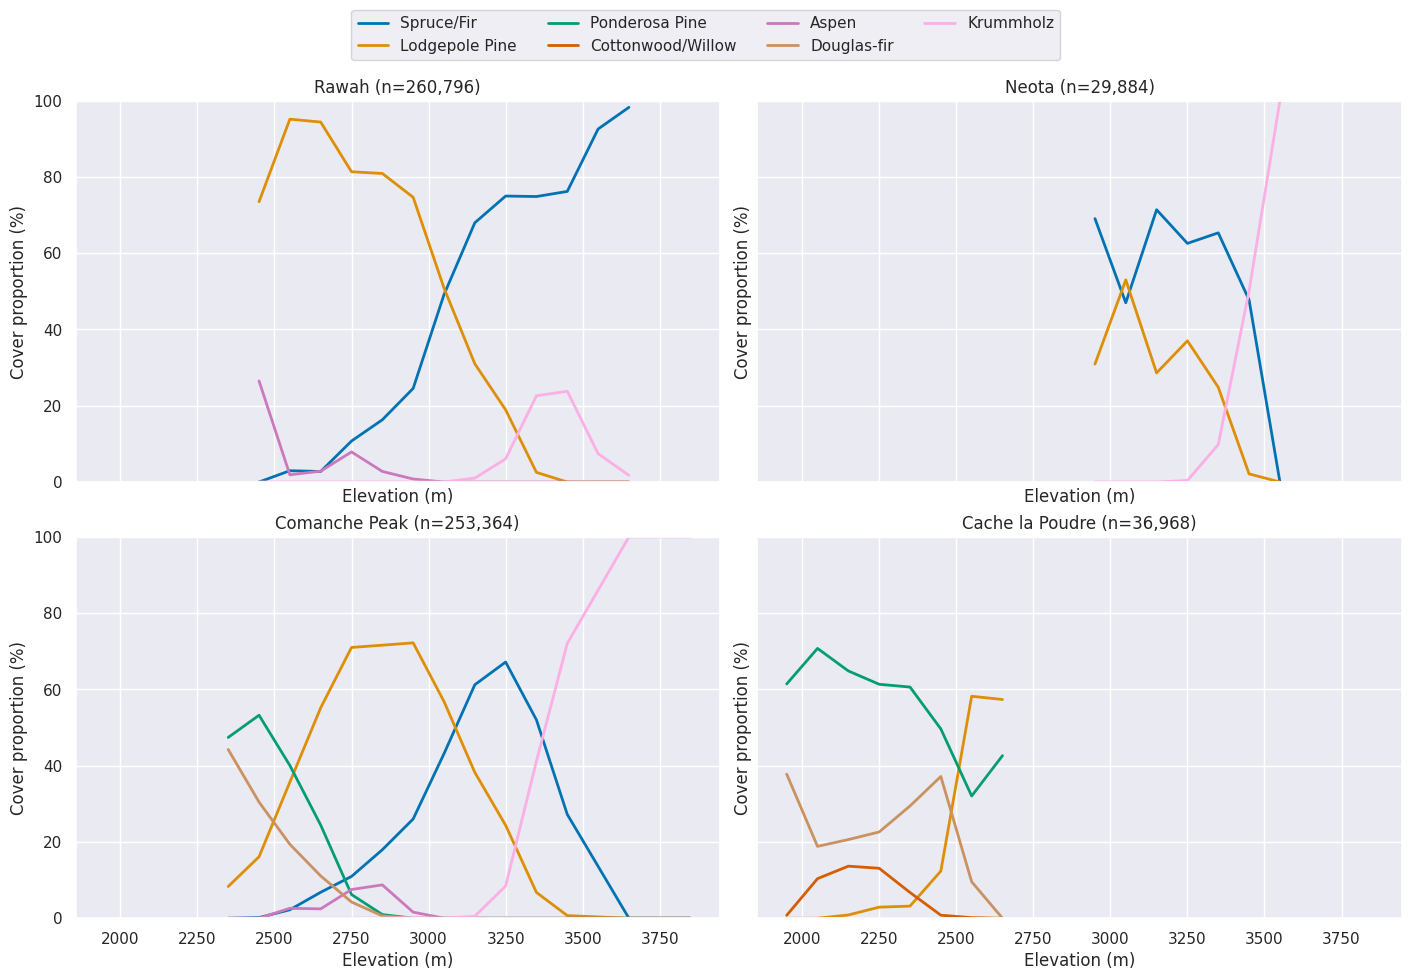

In [40]:
# Adapted from a group member's (Moinak Ghosh) exploratory notebook: fixed
# bin width instead of custom uneven bands, split by wilderness area, with a
# minimum-support threshold so thin bands aren't shown as if they were
# reliable. Changed here: column names match this notebook's own dataframe
# (Elevation, cover_type_name, wilderness_area_name) instead of the
# ELU_-prefixed columns and cover_names dict used in the original.
bin_width = 100
minimum_count = 100

# 1. Simplify binning: Floor division directly calculates the bin midpoints
df['Elevation_midpoint'] = (df['Elevation'] // bin_width) * bin_width + (bin_width / 2)

cover_order = list(cover_type_names.values())
wilderness_order = list(wilderness_names.values())
palette = sns.color_palette('colorblind', len(cover_order))

fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True, sharey=True, constrained_layout=True)

for ax, area in zip(axes.flat, wilderness_order):
    subset = df[df['wilderness_area_name'] == area]

    # 2. Crosstab directly on the numeric midpoints
    band_counts = pd.crosstab(
        subset['Elevation_midpoint'],
        subset['cover_type_name']
    ).reindex(columns=cover_order, fill_value=0)

    support = band_counts.sum(axis=1)

    # 3. Clean up threshold logic: filter out low-support bins BEFORE division
    valid_bands = band_counts[support >= minimum_count]
    proportions = valid_bands.div(support[support >= minimum_count], axis=0) * 100

    # 4. Plot using the index (midpoints) as the X-axis directly
    for cover, color in zip(cover_order, palette):
        ax.plot(proportions.index, proportions[cover], label=cover, color=color, linewidth=2)

    ax.set_title(f'{area} (n={len(subset):,})')
    ax.set_xlabel('Elevation (m)')
    ax.set_ylabel('Cover proportion (%)')
    ax.set_ylim(0, 100)

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 1.08), ncol=4)
plt.show()


This faceted multi-line chart makes the crossover points between cover types far more precise than the
pooled 5-band heatmap above. In Rawah and Comanche Peak, Lodgepole Pine
(orange) and Spruce/Fir (blue) cross almost exactly around 3,000 m, a clean
handoff rather than a vague overlap zone. Neota, being uniformly in higher
elevation, is dominated by Spruce/Fir across nearly its whole range, with
Krummholz only taking over right at the top above 3,500 m. Cache la Poudre
tells a completely different story: no Lodgepole Pine or Spruce/Fir curve
even appears, since that wilderness area does not reach high enough elevation
for those species. It is entirely Ponderosa Pine and Douglas-fir trading off
around 2,000-2,600 m, with Douglas-fir actually leading at the very lowest
elevations. This is the clearest confirmation, yet the elevation/cover-
type relationship is really four separate area-specific stories that happen
to average out into one smooth-looking overall pattern rather than one single
relationship holding uniformly everywhere.

### 2.8 Additional / derived features

1. `aspect_sin` / `aspect_cos` fixes the circular variable problem for
   PCA/LDA. Otherwise, 1 degree and 359 degrees would otherwise look maximally far apart.
2. `hillshade_range` takes the difference between `Hillshade_9am` and `Hillshade_3pm`.
3. `euclidean_distance_to_hydrology` combines `Horizontal_Distance_To_Hydrology` and `Vertical_Distance_To_Hydrology`.
4. `climatic_zone` / `geologic_zone` can be decoded from real USFS ELU soil codes, which turns 40 sparse dummies (9 useful, 12 flat) into 2 meaningful features.
5. `fire_road_ratio` explains the `Horizontal_Distance_To_Fire_Points` relative to the `Horizontal_Distance_To_Roadways`.

In [41]:
# correlation of each individual soil-type dummy column with the target
soil_target_corr = df[soil_cols].corrwith(df['Cover_Type']).abs().sort_values(ascending=False)
print("Strongest 5 soil types (by |correlation| with Cover_Type):")
print(soil_target_corr.head())
print()
print(f"Soil types with |corr| > 0.1: {(soil_target_corr > 0.1).sum()} / 40")
print(f"Soil types with |corr| < 0.02 (essentially no individual signal): {(soil_target_corr < 0.02).sum()} / 40")

Strongest 5 soil types (by |correlation| with Cover_Type):
Soil_Type10    0.243876
Soil_Type38    0.160170
Soil_Type39    0.155668
Soil_Type22    0.141746
Soil_Type23    0.135055
dtype: float64

Soil types with |corr| > 0.1: 9 / 40
Soil types with |corr| < 0.02 (essentially no individual signal): 12 / 40


Only 9 of 40 soil types clear 0.1 correlation with `Cover_Type`; 12 are
essentially flat. This supports grouping into broader categories. (Checking
individual soil type correlation this way was an idea picked up from a public
Kaggle/GitHub write-up on this dataset found via web search; the correlation
numbers themselves are computed directly from this data.)

In [42]:
# engineered features: sin/cos decomposition of the circular Aspect variable,
# hillshade swing over the day, and straight-line distance to water
df['aspect_sin'] = np.sin(np.deg2rad(df['Aspect']))
df['aspect_cos'] = np.cos(np.deg2rad(df['Aspect']))
df['hillshade_range'] = df['Hillshade_9am'] - df['Hillshade_3pm']
df['euclidean_distance_to_hydrology'] = np.sqrt(
    df['Horizontal_Distance_To_Hydrology']**2 + df['Vertical_Distance_To_Hydrology']**2
)
df[['Aspect','aspect_sin','aspect_cos','hillshade_range','euclidean_distance_to_hydrology']].head()

,Aspect,aspect_sin,aspect_cos,hillshade_range,euclidean_distance_to_hydrology
0,51,0.777146,0.629320,73,258.000000
1,56,0.829038,0.559193,69,212.084889
2,139,0.656059,-0.754710,99,275.769832
3,155,0.422618,-0.906308,116,269.235956
4,45,0.707107,0.707107,70,153.003268


In [43]:
# ELU codes from the dataset docs -- first digit = climatic zone, second = geologic zone
elu_codes = [2702,2703,2704,2705,2706,2717,3501,3502,4201,4703,4704,4744,4758,5101,
             5151,6101,6102,6731,7101,7102,7103,7201,7202,7700,7701,7702,7709,7710,
             7745,7746,7755,7756,7757,7790,8703,8707,8708,8771,8772,8776]

climatic_zone_names = {1:'lower montane dry', 2:'lower montane', 3:'montane dry',
                        4:'montane', 5:'montane dry and montane', 6:'montane and subalpine',
                        7:'subalpine', 8:'alpine'}
geologic_zone_names = {1:'alluvium', 2:'glacial', 3:'shale', 4:'sandstone',
                        5:'mixed sedimentary', 6:'unspecified', 7:'igneous and metamorphic', 8:'volcanic'}

soil_to_climatic = {i+1: climatic_zone_names[int(str(code)[0])] for i, code in enumerate(elu_codes)}
soil_to_geologic = {i+1: geologic_zone_names[int(str(code)[1])] for i, code in enumerate(elu_codes)}

df['climatic_zone'] = df['soil_type'].map(soil_to_climatic)
df['geologic_zone'] = df['soil_type'].map(soil_to_geologic)

df[['soil_type','climatic_zone','geologic_zone']].head()

,soil_type,climatic_zone,geologic_zone
0,29,subalpine,igneous and metamorphic
1,29,subalpine,igneous and metamorphic
2,12,montane,igneous and metamorphic
3,30,subalpine,igneous and metamorphic
4,29,subalpine,igneous and metamorphic


40 soil types can be broken down to 8 climatic and 8 geologic zones. This is being checked against
`Cover_Type`.

In [44]:
# cover-type composition within each climatic zone, in low-to-high elevation order
climatic_order = ['lower montane dry','lower montane','montane dry','montane',
                   'montane dry and montane','montane and subalpine','subalpine','alpine']
ct = pd.crosstab(df['climatic_zone'], df['cover_type_name'], normalize='index') * 100
ct.reindex(climatic_order).round(1)

cover_type_name,Aspen,Cottonwood/Willow,Douglas-fir,Krummholz,Lodgepole Pine,Ponderosa Pine,Spruce/Fir
climatic_zone,,,,,,,
lower montane dry,NaN,NaN,NaN,NaN,NaN,NaN,NaN
lower montane,2.4,5.1,13.4,0.2,17.3,61.1,0.5
montane dry,0.0,0.0,0.0,0.0,84.9,0.0,15.1
montane,2.4,0.3,10.7,0.0,65.6,13.8,7.2
montane dry and montane,0.0,25.7,55.0,0.0,0.0,19.3,0.0
montane and subalpine,9.9,6.0,11.8,0.0,53.4,7.8,11.3
subalpine,1.4,0.0,0.3,1.0,52.1,0.0,45.2
alpine,0.0,0.0,0.0,41.0,3.7,0.0,55.4


Going through the pattern zone by zone:
- `lower montane dry` doesn't appear at all in this data (entirely NaN). None
  of the 40 soil codes present across these four wilderness areas happen to
  fall into that particular climatic zone, so this is genuinely an absent
  category rather than a data gap.
- `lower montane` is mostly Ponderosa Pine (61%), with some Lodgepole Pine and
  Douglas-fir mixed in, which is consistent with the lower elevation end of the
  spectrum.
- `subalpine` and `alpine` are the two cleanest, most distinct bands.
  `subalpine` splits almost entirely between Lodgepole Pine (52%) and
  Spruce/Fir (45%), while `alpine` is almost entirely Spruce/Fir (55%) and
  Krummholz (41%). This is exactly the high elevation species mix that we would
  expect.
- The middle zones are considerably messier than a clean progression though.
  `montane dry` turns out to be 85% Lodgepole Pine, not dominated by
  Ponderosa Pine or Douglas-fir the way the name might suggest, and `montane
  dry and montane` is mostly Douglas-fir (55%) and Cottonwood/Willow (26%). Lodgepole Pine in particular behaves like a real ecological
  generalist here, showing up in meaningful numbers across almost every
  climatic zone rather than sticking to one elevation band, which is
  consistent with it being the single largest cover type in the dataset
  overall (section 2.4).

This is a good confirmation that the soil type codes are not arbitrary labels.
They carry real, physically grounded information that mostly lines up with
elevation, with some genuine ecological messiness in the middle zones rather
than a perfectly clean split.

## 3. Exceptional Work: Dimensionality Reduction (PCA / LDA)

Constructed below is the pairplot preview before performing PCA. We used the same approach as the Iris example shown in class.

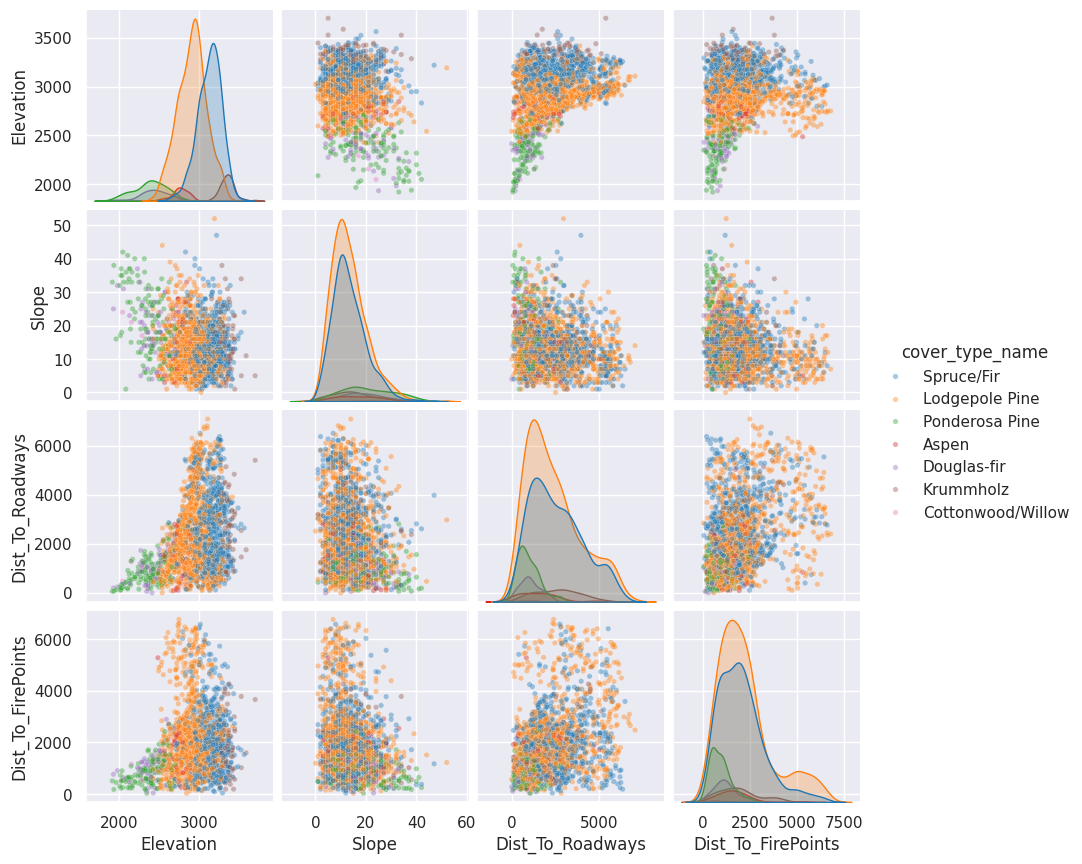

In [45]:
# using sns.pairplot(df, hue=<target>) before PCA/LDA is the same pattern as
# the Iris example in course companion notebook 03__Dimension_Reduction.ipynb
# (sns.pairplot(df, hue="target")). Adapted here to this dataset's own columns
# and a stratified sample rather than plotting all of Iris's 150 rows.

# the real column names are long enough that they overlap on the plot axes,
# so using short aliases just for this chart's labels
short_names = {'Elevation': 'Elevation', 'Slope': 'Slope',
               'Horizontal_Distance_To_Roadways': 'Dist_To_Roadways',
               'Horizontal_Distance_To_Fire_Points': 'Dist_To_FirePoints'}

pairplot_sample = df.sample(n=2000, random_state=42).rename(columns=short_names)

g = sns.pairplot(pairplot_sample, vars=list(short_names.values()),
                  hue='cover_type_name', palette='tab10', plot_kws={'alpha': 0.4, 's': 15}, height=2.2)
g.fig.subplots_adjust(left=0.08, bottom=0.08)
plt.show()

Before running any PCA, `Elevation` is clearly doing most of the
separating work here. Its histograms on the diagonal are visually the most
separated by color out of the four attributes shown, and the scatter panels
that include `Elevation` show the clearest banding by cover type. The other
three attributes (`Slope`, `Dist_To_Roadways`, and `Dist_To_FirePoints`) mix together
much more, without any clear separation by color. This is a good
preview of what the PCA and LDA analysis confirm more formally just below.

We plan to run PCA to project the numeric attributes down to two dimensions and see
how well the resulting classes separate visually. Then, we compare that against
a supervised LDA projection on the same data. Given the size of this dataset
(581k rows), using a stratified sample for both plots keeps them both readable and
reasonably fast to render while still preserving the true class proportions.

Below is the full version of the pairplot we created earlier, with all 10 numeric attributes. We rely on the parameter `corner=True` to halve the panels.

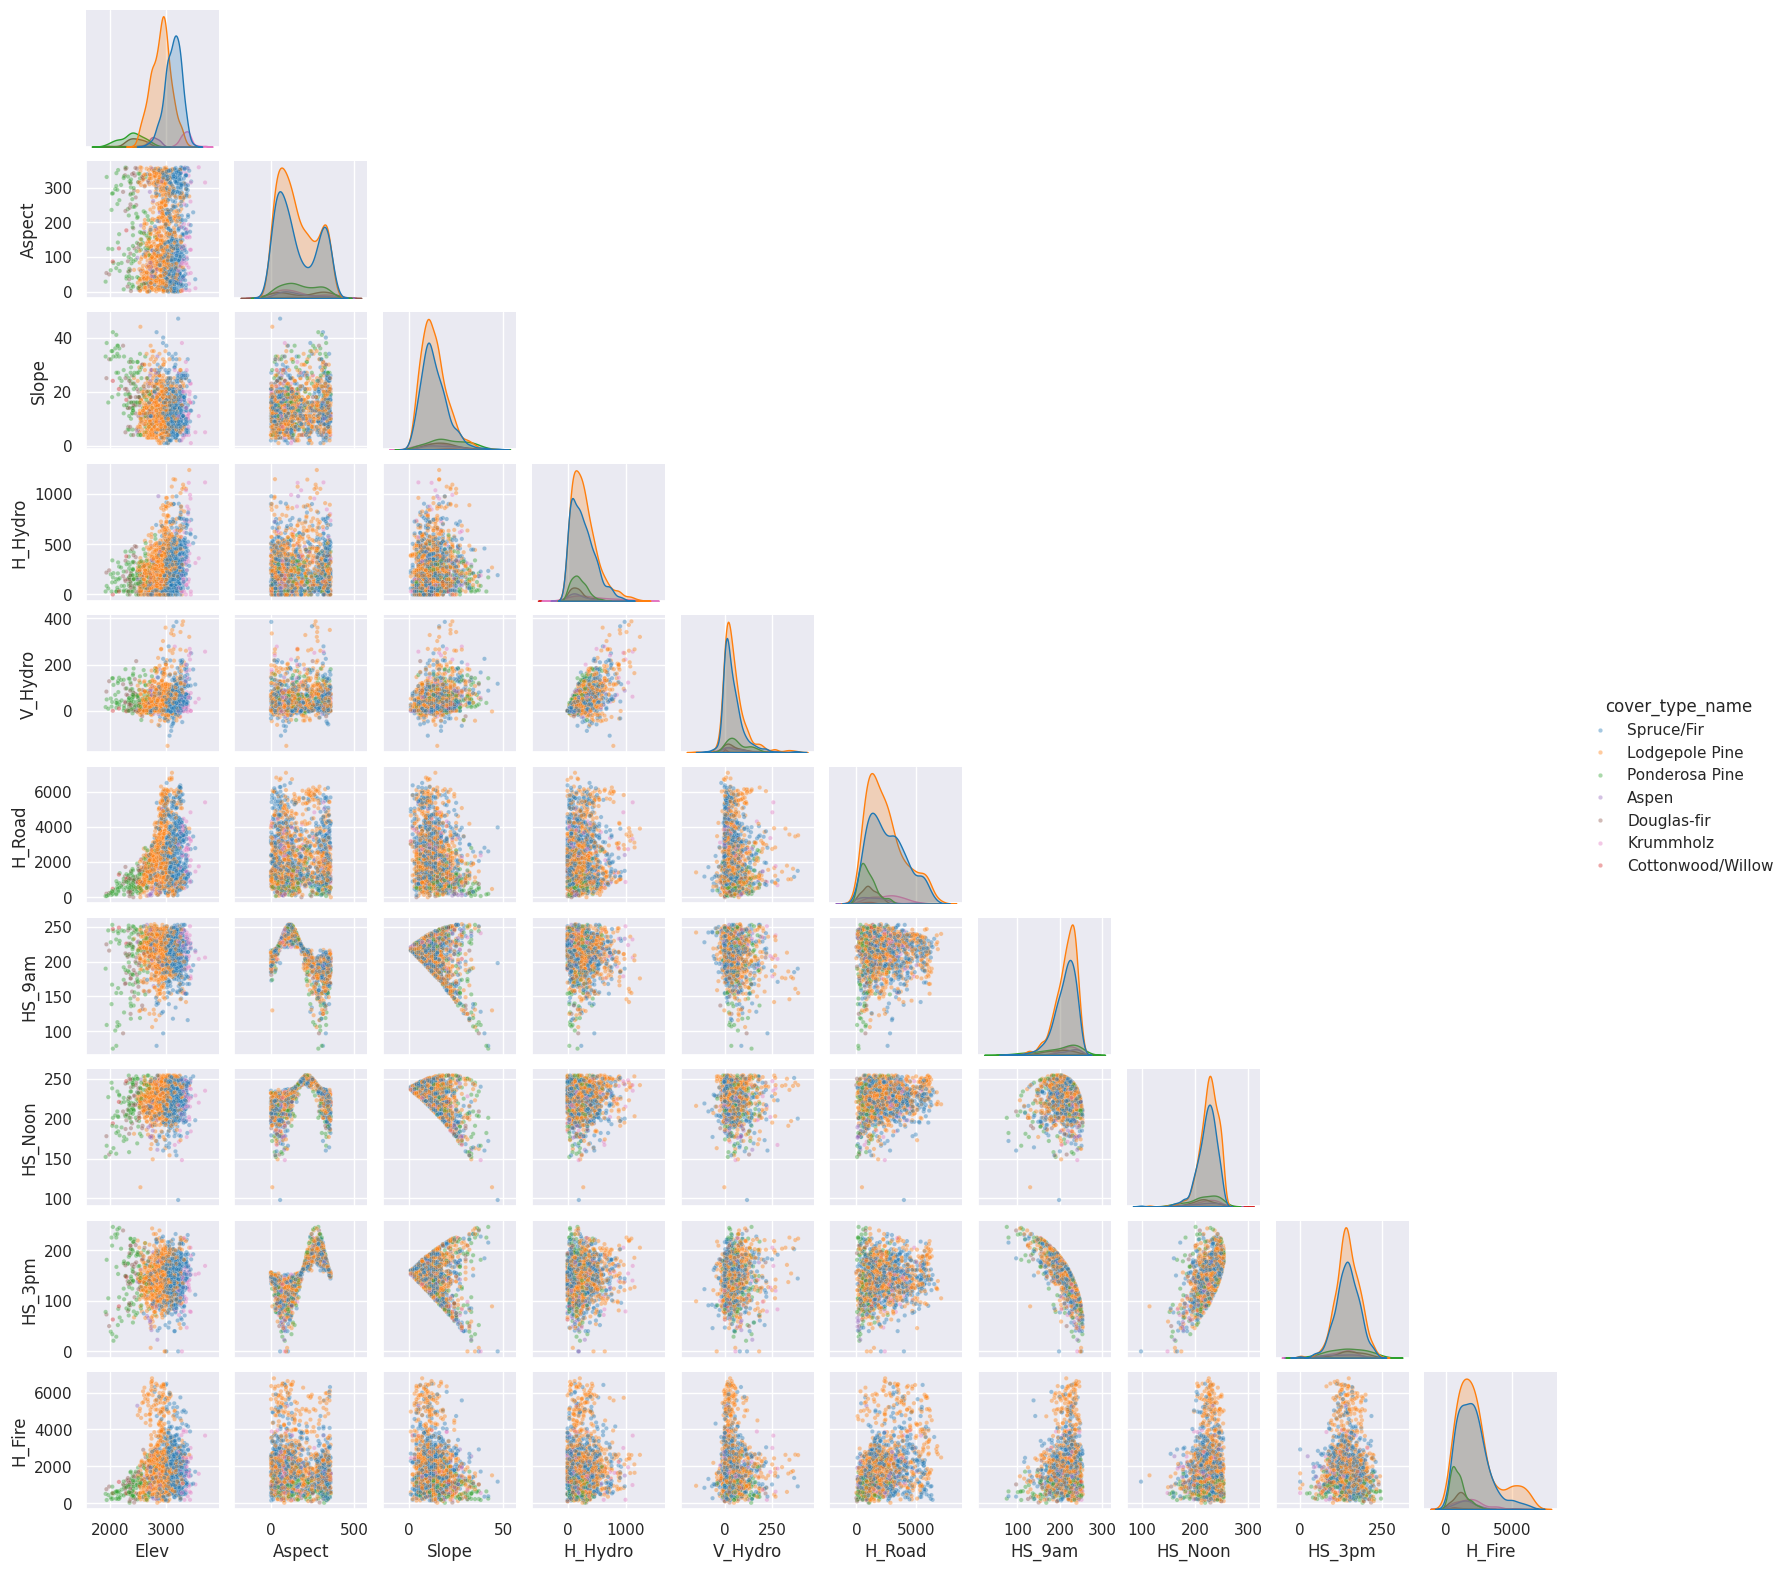

In [46]:
pairplot_full_sample = df.sample(n=1500, random_state=42)

# same fixed color map used for the PCA/LDA plots later in section 3, defined
# here too since this pairplot comes first
cover_type_colors = {
    'Spruce/Fir': '#1f77b4', 'Lodgepole Pine': '#ff7f0e', 'Ponderosa Pine': '#2ca02c',
    'Cottonwood/Willow': '#d62728', 'Aspen': '#9467bd', 'Douglas-fir': '#8c564b',
    'Krummholz': '#e377c2'
}

short_names_full = {
    'Elevation': 'Elev', 'Aspect': 'Aspect', 'Slope': 'Slope',
    'Horizontal_Distance_To_Hydrology': 'H_Hydro', 'Vertical_Distance_To_Hydrology': 'V_Hydro',
    'Horizontal_Distance_To_Roadways': 'H_Road', 'Hillshade_9am': 'HS_9am',
    'Hillshade_Noon': 'HS_Noon', 'Hillshade_3pm': 'HS_3pm',
    'Horizontal_Distance_To_Fire_Points': 'H_Fire'
}
plot_df_full = pairplot_full_sample[numeric_cols + ['cover_type_name']].rename(columns=short_names_full)

g = sns.pairplot(plot_df_full, hue='cover_type_name', palette=cover_type_colors,
                  height=1.6, corner=True, plot_kws={'alpha': 0.4, 's': 10})
plt.show()

We get the same overall conclusion as the smaller 4-feature version but just far more
obvious once everything is laid out together. The `Elev` row and column is
the only one where the colors clearly separate into distinct bands, which is visible
both in the scatter panels and in the `Elev` density curve on the
diagonal, where Spruce/Fir and Lodgepole Pine peak at clearly different
elevation values. Essentially, every other panel is a solid, undifferentiated
mix of colors with no real separation between classes, which lines up with
everything found so far in this notebook: elevation is doing almost all of
the discriminating work, and the other 9 attributes are mostly not separating
cover types on their own. Two more things worth noting: the `HS_9am`/`HS_3pm`
panel traces out a clean curved boundary rather than a shapeless cloud of
points, which is a nice visual confirmation of the -0.78 correlation between those two
columns found in the heatmap back in section 2.6. Additionally, the `Aspect` diagonal
still shows the same double-peaked shape seen in the polar histogram back in
section 2.5.

In [47]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split

feature_cols = numeric_cols + ['aspect_sin', 'aspect_cos']

# stratified sample of 20,000 rows for the plots
df_sample, _ = train_test_split(df, train_size=20000, stratify=df['Cover_Type'], random_state=42)

X = df_sample[feature_cols].values
y = df_sample['cover_type_name'].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print('Explained variance ratio:', pca.explained_variance_ratio_)
print('Total variance captured by 2 components: {:.1f}%'.format(pca.explained_variance_ratio_.sum()*100))

Explained variance ratio: [0.28684983 0.19035191]
Total variance captured by 2 components: 47.7%


In [48]:
# get_feature_names_from_weights() below is adapted from the course companion
# notebook 03__Dimension_Reduction.ipynb (used there on the Iris PCA/LDA
# components). Same function body, just applied here to this dataset's own
# feature_cols/pca.components_ instead of Iris's 4 features.
def get_feature_names_from_weights(weights, names):
    tmp_array = []
    for comp in weights:
        s = ''
        for fidx, f in enumerate(names):
            if fidx > 0 and comp[fidx] >= 0:
                s += '+'
            s += '%.2f*%s ' % (comp[fidx], f)
        tmp_array.append(s)
    return tmp_array

for i, s in enumerate(get_feature_names_from_weights(pca.components_, feature_cols)):
    print(f'PC{i+1}: {s}')

PC1: -0.03*Elevation -0.44*Aspect -0.01*Slope -0.06*Horizontal_Distance_To_Hydrology -0.08*Vertical_Distance_To_Hydrology -0.04*Horizontal_Distance_To_Roadways +0.44*Hillshade_9am -0.26*Hillshade_Noon -0.51*Hillshade_3pm +0.07*Horizontal_Distance_To_Fire_Points +0.51*aspect_sin -0.01*aspect_cos 
PC2: 0.32*Elevation -0.03*Aspect -0.48*Slope +0.03*Horizontal_Distance_To_Hydrology -0.19*Vertical_Distance_To_Hydrology +0.35*Horizontal_Distance_To_Roadways +0.29*Hillshade_9am +0.49*Hillshade_Noon +0.09*Hillshade_3pm +0.26*Horizontal_Distance_To_Fire_Points +0.04*aspect_sin -0.32*aspect_cos 


Looking at what each principal component is actually built from, PC1 is
dominated by `aspect_sin`/`aspect_cos` and `Hillshade_9am`/`Hillshade_3pm`,
which is essentially the whole sun exposure and orientation group. PC2 is dominated
by `Hillshade_Noon`, `Slope`, and a smaller contribution from
`Horizontal_Distance_To_Roadways` and `Elevation`. This is a little surprising
at first since `Elevation` turned out to be the strongest predictor of `Cover_Type` back in section 2.7, but it makes sense once you remember that PCA only
optimizes for variance, not for separating classes. The `Aspect`/hillshade
group simply happens to have more spread in the standardized data, so PCA
prioritizes capturing that variance, even though `Elevation` is actually more
useful for the real classification question at hand. `Elevation` still shows up
in the mix (within PC2, alongside `Slope` and `Horizontal_Distance_To_Roadways`), not just as
the dominant contributor to either axis. This is exactly the kind of gap
where LDA, which explicitly optimizes for class separation rather than
raw variance, ends up telling a more useful story than PCA, as shown next.

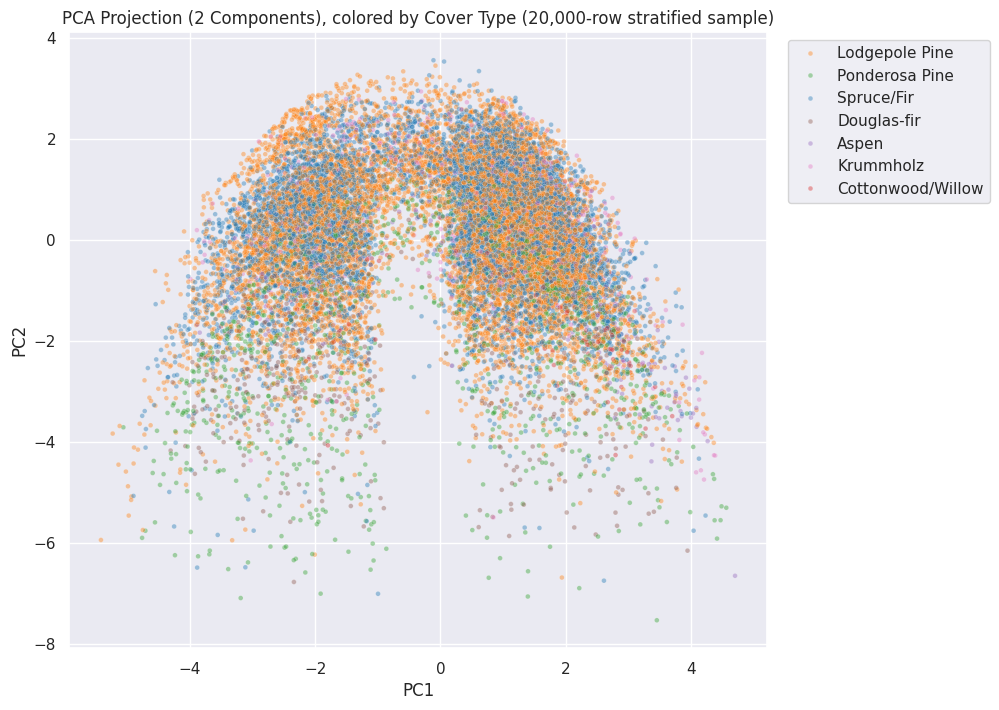

In [49]:
# fixed color per cover type, reused across the PCA/LDA plots (static + interactive)
# so the same class is always the same color everywhere
cover_type_colors = {
    'Spruce/Fir': '#1f77b4', 'Lodgepole Pine': '#ff7f0e', 'Ponderosa Pine': '#2ca02c',
    'Cottonwood/Willow': '#d62728', 'Aspen': '#9467bd', 'Douglas-fir': '#8c564b',
    'Krummholz': '#e377c2'
}

df_pca = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
df_pca['cover_type'] = y

plt.figure(figsize=(9, 8))
ax = sns.scatterplot(data=df_pca, x='PC1', y='PC2', hue='cover_type', alpha=0.4, s=12, palette=cover_type_colors)
plt.title('PCA Projection (2 Components), colored by Cover Type (20,000-row stratified sample)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')

# capturing the exact axis limits matplotlib settled on, to reuse on the
# interactive version below so both plots are on the same scale
pca_xlim, pca_ylim = ax.get_xlim(), ax.get_ylim()

plt.show()

This shows decent separation, especially for the two classes at the
elevation extremes: Cottonwood/Willow (lowest elevation) and Krummholz
(highest elevation), as they form fairly distinct, separable clusters. That tracks
with how strong `Elevation` separated these classes back in section 2.7
since `Elevation` dominates the variance among the numeric features. Therefore, PC1 is
largely picking up that same underlying signal. The three middle elevation
classes (Lodgepole Pine, Spruce/Fir, and Douglas-fir) still overlap heavily
though, which is consistent with them being ecologically similar species
that occur together across overlapping elevation bands. They are genuinely difficult
to tell apart using cartographic data alone.

We also constructed an **interactive PCA plot** that has the same scale as the static plot. Click a legend entry to
hide/show a class, double-click to isolate it. Hover shows `Elevation` and
`Wilderness_Area` per point.

In [50]:
import sys
import plotly.express as px
import plotly.io as pio

# Colab's output frames don't reliably load Plotly via a raw CDN <script> tag,
# so pointing it at Colab's own built-in renderer instead when running there
if 'google.colab' in sys.modules:
    pio.renderers.default = 'colab'

df_pca_hover = df_pca.copy()
df_pca_hover['Elevation'] = df_sample['Elevation'].values
df_pca_hover['Wilderness_Area'] = df_sample['wilderness_area_name'].values

fig = px.scatter(df_pca_hover, x='PC1', y='PC2', color='cover_type',
                  hover_data=['Elevation', 'Wilderness_Area'],
                  opacity=0.5, color_discrete_map=cover_type_colors,
                  category_orders={'cover_type': list(cover_type_colors.keys())},
                  title='Interactive PCA Projection (click a legend entry to hide/show that cover '
                        'type, double-click to isolate it, hover for details, scroll/drag to zoom)')
fig.update_traces(marker=dict(size=4))
fig.update_layout(height=650, legend_title_text='Cover Type (click to toggle)')

# reusing the exact axis limits captured from the static matplotlib plot above
fig.update_xaxes(range=list(pca_xlim))
fig.update_yaxes(range=list(pca_ylim))
fig.show()

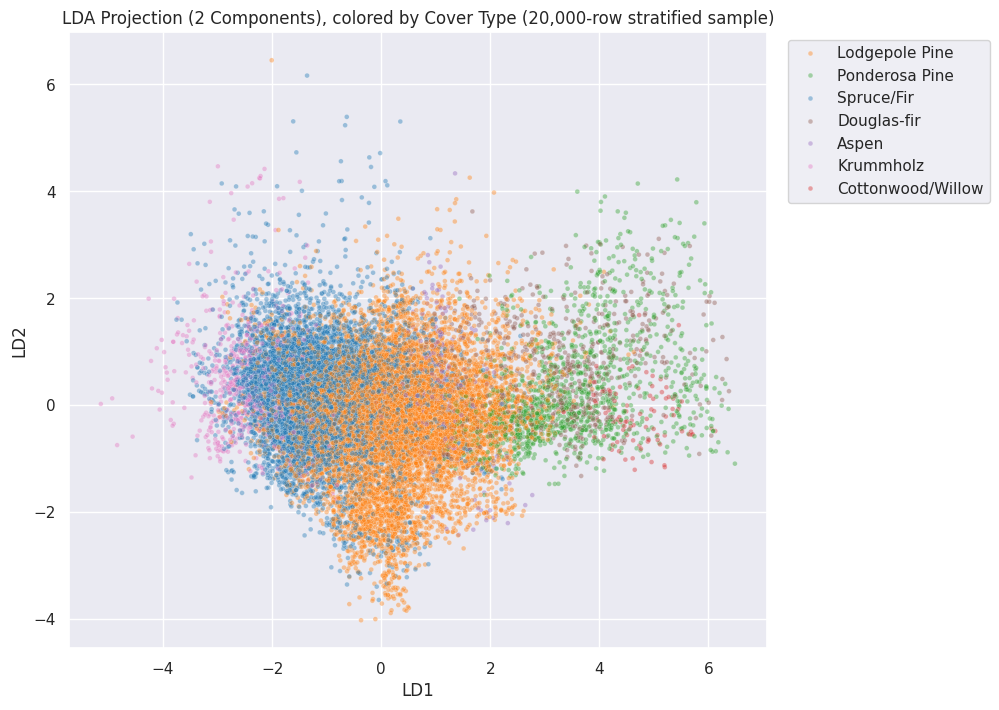

In [51]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA

y_numeric = df_sample['Cover_Type'].values
lda = LDA(n_components=2)
X_lda = lda.fit(X_scaled, y_numeric).transform(X_scaled)

df_lda = pd.DataFrame(X_lda, columns=['LD1', 'LD2'])
df_lda['cover_type'] = y

plt.figure(figsize=(9, 8))
ax = sns.scatterplot(data=df_lda, x='LD1', y='LD2', hue='cover_type', alpha=0.4, s=12, palette=cover_type_colors)
plt.title('LDA Projection (2 Components), colored by Cover Type (20,000-row stratified sample)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')

# capturing the exact axis limits, same reason as the PCA plot above
lda_xlim, lda_ylim = ax.get_xlim(), ax.get_ylim()

plt.show()

This LDA plot shows a much cleaner separation than the PCA plot, which makes sense
since LDA explicitly optimizes for between classes separation rather than just
overall variance the way PCA does. Almost all 7 classes now occupy their own
distinguishable region in the 2D projection, with the same three
middle elevation conifers (Lodgepole Pine, Spruce/Fir, and Douglas-fir) still forming
the main area of overlap. That matches exactly what showed up as the toughest
group to separate in the elevation boxplot back in section 2.7. This is a
good sign that a real classifier trained on these cartographic variables,
especially elevation combined with the wilderness area and soil categorical
information, should perform reasonably well overall, with most of the
remaining confusion concentrated among those three specific species.

Just like the interactive PCA plot, we constructed an **interactive LDA plot** that has the same scaling as the LDA plot constructed earlier. Click legend entries to toggle.

In [52]:
df_lda_hover = df_lda.copy()
df_lda_hover['Elevation'] = df_sample['Elevation'].values
df_lda_hover['Wilderness_Area'] = df_sample['wilderness_area_name'].values

fig = px.scatter(df_lda_hover, x='LD1', y='LD2', color='cover_type',
                  hover_data=['Elevation', 'Wilderness_Area'],
                  opacity=0.5, color_discrete_map=cover_type_colors,
                  category_orders={'cover_type': list(cover_type_colors.keys())},
                  title='Interactive LDA Projection (click a legend entry to hide/show that cover '
                        'type, double-click to isolate it, hover for details, scroll/drag to zoom)')
fig.update_traces(marker=dict(size=4))
fig.update_layout(height=650, legend_title_text='Cover Type (click to toggle)')

# reusing the exact axis limits captured from the static matplotlib plot above
fig.update_xaxes(range=list(lda_xlim))
fig.update_yaxes(range=list(lda_ylim))
fig.show()

To explain one more angle on those three overlapping conifers, we constructed a parallel
coordinates plot. This was not used for all 7 classes since many
overlapping colors spread across 10 axes turns into unreadable visual noise
very quick, especially at this scale, and it would not reveal anything that the
PCA/LDA plots above do not already show more clear. However, restricted to just
the three classes that keep showing up as hard to separate throughout this
analysis (Lodgepole Pine, Spruce/Fir, and Douglas-fir), it becomes a genuinely
useful complement. Instead of collapsing everything down to two dimensions
the way PCA and LDA do, this shows all 10 numeric dimensions side by side at
once, which can reveal exactly which specific attributes are driving the
overlap between these classes, or driving separation where it exists, rather
than just confirming that the overlap is present.

Sampling 300 rows per class here keeps the plot readable, standardizing every
attribute puts them all on a common scale (parallel coordinates only make
sense when every axis is comparable), and swapping raw `Aspect` for
`aspect_sin`/`aspect_cos` avoids the same circular variable distortion
discussed for the PCA/LDA work above.

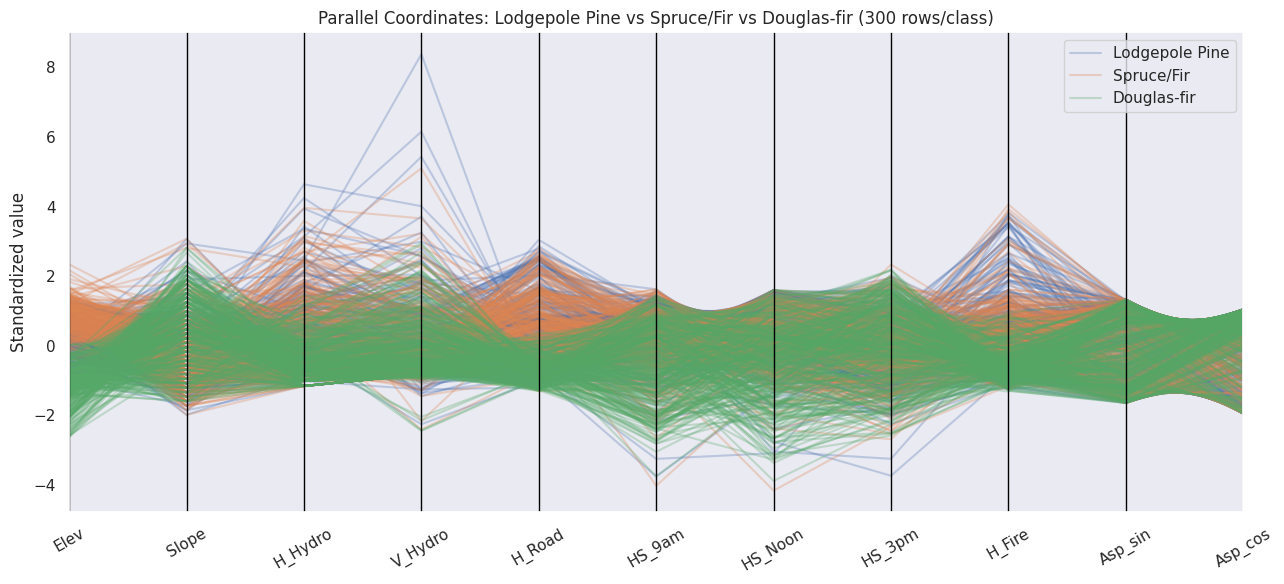

In [53]:
# General approach (normalize numeric columns, then plot with
# pandas.plotting.parallel_coordinates) is adapted from a Titanic-dataset
# parallel coordinates example from the course materials (df_sub/df_normalized
# pattern, jitter mentioned for categorical axes). Changed here: normalizing
# by z-score instead of that example's own scaling, restricting to 3 cover
# types instead of a full column subset, using aspect_sin/aspect_cos instead
# of a raw categorical like Sex, and no jitter added since all axes here are
# continuous numeric rather than categorical.
from pandas.plotting import parallel_coordinates

target_classes = ['Lodgepole Pine', 'Spruce/Fir', 'Douglas-fir']
pc_sample = pd.concat([
    df[df['cover_type_name'] == cls].sample(n=300, random_state=42)
    for cls in target_classes
])

pc_feature_cols = [c for c in numeric_cols if c != 'Aspect'] + ['aspect_sin', 'aspect_cos']
pc_short_names = {
    'Elevation': 'Elev', 'Slope': 'Slope',
    'Horizontal_Distance_To_Hydrology': 'H_Hydro', 'Vertical_Distance_To_Hydrology': 'V_Hydro',
    'Horizontal_Distance_To_Roadways': 'H_Road', 'Hillshade_9am': 'HS_9am',
    'Hillshade_Noon': 'HS_Noon', 'Hillshade_3pm': 'HS_3pm',
    'Horizontal_Distance_To_Fire_Points': 'H_Fire', 'aspect_sin': 'Asp_sin', 'aspect_cos': 'Asp_cos'
}

X = pc_sample[pc_feature_cols].copy()
X_norm = (X - X.mean()) / X.std()
X_norm.columns = [pc_short_names[c] for c in pc_feature_cols]
X_norm['cover_type_name'] = pc_sample['cover_type_name'].values

plt.figure(figsize=(13, 6))
parallel_coordinates(X_norm, 'cover_type_name', color=['#4C72B0', '#DD8452', '#55A868'], alpha=0.3)
plt.xticks(rotation=30)
plt.ylabel('Standardized value')
plt.title('Parallel Coordinates: Lodgepole Pine vs Spruce/Fir vs Douglas-fir (300 rows/class)')
plt.tight_layout()
plt.show()

This parallel coordinates plot reveals something the 2D plots did not make as obvious: it is not the
case that all three classes are equally tangled with each other everywhere. Rather,
Douglas-fir (green) actually splits off fairly visibly on `Elev` (sitting
noticeably lower than the other two) and on `H_Road` and `H_Fire` (both
noticeably lower as well). That is consistent with the elevation band story
from earlier sections, since Douglas-fir is concentrated in the Cache la Poudre wilderness area (located at lower elevation and is
more accessible by road). Checking the actual
group averages confirms this directly: Douglas-fir averages roughly 2,403 m in
elevation versus about 2,939 m for Lodgepole Pine and 3,133 m for Spruce/Fir, which is a
real and meaningful gap on that one dimension alone.

Lodgepole Pine and Spruce/Fir (blue and orange), on the other hand, stay
genuinely tangled together across nearly every single axis, not just one or
two. Their lines cross and overlap constantly all the way from `Elev` through
`Asp_cos`. This is a more precise version of what the LDA plot already
hinted at: the "three-way overlap" identified earlier wasn't really a
three-way problem at all. It is mostly a two-way problem, specifically
Lodgepole Pine versus Spruce/Fir, with Douglas-fir actually being reasonably
separable on elevation and accessibility once we look at the right
individual attributes instead of a collapsed 2D projection.

## Summary of Key Findings

- No missing values, no duplicates.
- Target imbalanced: Lodgepole Pine approximately 48.8% and Spruce/Fir approximately 36.5% dominate, while
  Cottonwood/Willow under 0.5%. Use macro-F1/confusion matrix over accuracy.
- Outliers are legitimate terrain values, not errors.
- `Aspect` needs sin/cos decomposition for any distance based method.
- `Elevation` is by far the strongest predictor, matching known forest
  ecology. `Wilderness_Area_Name` and `Horizontal_Distance_To_Roadways` track the same gradient.
- PCA separates classes reasonably well since `Elevation` dominates numeric
  variance. LDA separates better, isolating all classes except Lodgepole Pine,
  Spruce/Fir, and Douglas-fir.
- Wilderness area differences are mostly an elevation story (Neota highest,
  Cache la Poudre lowest).
- Only 9 of 40 soil types carry meaningful individual signal, supporting
  grouping into broader categories.